# Flood Mapping That Still Works Under Cloud — Enhanced Implementation
## Sensor-aware fusion with per-availability missed-flood calibration (Sen1Floods11 v1.1, PyTorch, Colab)

**Sections:** 1 Overview · 2 Environment · 3 Download · 4 Index/splits · 5 Raster preprocessing · 6 Cache · 7 Dataset & clouds · 8 Sanity checks · 9 Models · 10 Losses · 11 Config · 12 Training · 13 Checkpoints · 14 Calibration · 15 Final evaluation · 16 Cloud robustness · 17 Ablations · 18 Probability calibration/uncertainty · 19 Figures · 20 Export · 21 Metadata · 22 Deployment.

### What this notebook does (vs. the original FINAL notebook)
| Area | Original | Here |
|---|---|---|
| Availability states | radar-only + both trained; optical-only never trained | **all three** sampled in training and evaluated |
| Availability embedding | defined, **never used** in forward | injected into gate + FiLM on fused features |
| Optical-feature head | missing | radar→optical feature head, supervised by optical features when both present |
| Baselines | radar U-Net only | radar, **optical**, **early-fusion**, **sensor-dropout fusion (no consistency)** |
| Threshold calibration | pooled-pixel empirical, same val set as model selection | **separate calibration split** (carved from the official validation chips), per-state; **chip-level conformal risk control** (finite-sample, with stated assumptions) + empirical pixel-pooled variant, clearly labelled |
| Probability calibration | none | Brier, ECE, reliability diagrams, temperature scaling (fit on calibration split) |
| Uncertainty | none | MC-Dropout (optional) |
| Cloud evaluation | fusion only | all states × severities, fixed per-chip seeds |
| Statistics | pooled only | per-chip + chip-level bootstrap CIs, multi-seed support |
| Data pipeline | in-memory dict cache re-filled every session | persistent, validated `.npy` cache (fingerprinted), mmap loading, timing |
| Checkpoints | best weights only | full resume (model/opt/sched/scaler/history/RNG), config-compatibility check |

### Honest scope statements (read before quoting results)
* Synthetic clouds are a **stress test**, not atmospheric physics.
* The conformal procedure gives a **marginal, chip-level** guarantee on the *per-chip miss rate averaged over exchangeable chips*; it is **not** per-pixel, per-image, or per-event, and chips from the same flood event are *not* exactly exchangeable. See Section 14.
* No Bangladesh data are used. Do **not** claim Bangladesh validation.
* Area (m²/km²) is **not** reported: chips are resampled 512→128, and we only report pixel counts plus an *approximate* area derived from raster metadata, flagged as approximate (Section 15).
* The sandbox where this notebook was authored had no PyTorch/GPU/dataset. Static checks and NumPy-level unit tests were executed there; **nothing in this notebook has been executed end-to-end by the author.** The run-time self-tests in Section 9–10 and 13 will run when *you* execute it.

## 2. Environment setup
Run-mode switch lives in Section 11 (`RUN_MODE`). The dependencies cell installs only what Colab lacks.

In [1]:
# 2.1 — dependencies, imports, seeds, device
%pip -q install rasterio tqdm

import os, re, json, math, random, shutil, subprocess, sys, time, hashlib, copy, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import rasterio
from rasterio.warp import reproject, Resampling

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = False

# Run mode: "smoke" (pipeline check on a few chips, 2 epochs), "one_day" (default), "long" (more epochs/seeds)
RUN_MODE = "one_day"
assert RUN_MODE in ("smoke", "one_day", "long")

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def stable_seed(text):
    """Process-independent 32-bit seed from a string (unlike hash())."""
    return int(hashlib.sha256(text.encode("utf-8")).hexdigest()[:8], 16)

print("Python", sys.version.split()[0], "| torch", torch.__version__, "| device", DEVICE,
      "| rasterio", rasterio.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

Note: you may need to restart the kernel to use updated packages.
Python 3.13.16 | torch 2.11.0+cu130 | device cuda | rasterio 1.5.2 | numpy 2.1.3 | pandas 2.3.3
GPU: Tesla T4


## 3. Dataset download
`gsutil rsync` is idempotent. The four official folders are synced: S1Hand, S2Hand, LabelHand and `splits/flood_handlabeled`. If you set `USE_DRIVE=True` (Section 11 below, but the flag is read here) the dataset itself is **not** copied to Drive (≈ 1–2 GB) — only the *preprocessed cache* and results are persisted.

In [2]:
# 3.1 — paths and download
ROOT = Path("/kaggle/working/sen1floods11")
S1_DIR, S2_DIR, LABEL_DIR, SPLIT_DIR = ROOT/"S1Hand", ROOT/"S2Hand", ROOT/"LabelHand", ROOT/"splits"
for d in (S1_DIR, S2_DIR, LABEL_DIR, SPLIT_DIR): d.mkdir(parents=True, exist_ok=True)

def run_gsutil_sync(source, destination):
    if shutil.which("gsutil") is None:
        raise RuntimeError("gsutil not found. Install Google Cloud SDK or download the public folders manually "
                           "(same directory names).")
    cmd = ["gsutil", "-m", "rsync", "-r", source, str(destination)]
    print("Running:", " ".join(cmd)); subprocess.run(cmd, check=True)

BASE = "gs://sen1floods11/v1.1"
run_gsutil_sync(f"{BASE}/data/flood_events/HandLabeled/S1Hand", S1_DIR)
run_gsutil_sync(f"{BASE}/data/flood_events/HandLabeled/S2Hand", S2_DIR)
run_gsutil_sync(f"{BASE}/data/flood_events/HandLabeled/LabelHand", LABEL_DIR)
run_gsutil_sync(f"{BASE}/splits/flood_handlabeled", SPLIT_DIR)
for n, d in [("S1", S1_DIR), ("S2", S2_DIR), ("Label", LABEL_DIR)]:
    print(n, "GeoTIFFs:", len(list(d.rglob("*.tif"))))
print("Split CSVs:", [p.name for p in SPLIT_DIR.rglob("*.csv")])

Running: gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /kaggle/working/sen1floods11/S1Hand



both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_379434_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_129334_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_195474_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_242570_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events

Running: gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand /kaggle/working/sen1floods11/S2Hand



both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_312675_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_195474_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_103757_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_23014_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_129334_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_314919_S2Hand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/

Running: gsutil -m rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /kaggle/working/sen1floods11/LabelHand



both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Ghana_1033830_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_195474_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_129334_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_23014_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_294583_LabelHand.tif...
Copying gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif...
Copying gs://s

Running: gsutil -m rsync -r gs://sen1floods11/v1.1/splits/flood_handlabeled /kaggle/working/sen1floods11/splits



both the source and destination. Your crcmod installation isn't using the
module's C extension, so checksumming will run very slowly. If this is your
first rsync since updating gsutil, this rsync can take significantly longer than
usual. For help installing the extension, please see "gsutil help crcmod".

Building synchronization state...
Starting synchronization...
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_bolivia_data.csv...
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_train_data.csv... 
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_valid_data.csv... 
Copying gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_test_data.csv...  
/ [4/4 files][ 23.5 KiB/ 23.5 KiB] 100% Done                                    
Operation completed over 4 objects/23.5 KiB.                                     


S1 GeoTIFFs: 446
S2 GeoTIFFs: 446
Label GeoTIFFs: 446
Split CSVs: ['flood_test_data.csv', 'flood_valid_data.csv', 'flood_bolivia_data.csv', 'flood_train_data.csv']


## 4. File indexing and official splits
Preserved from the original (it worked: 235 / 82 / 83 with zero overlap). Changes: (i) the **Bolivia held-out region** CSV is also parsed because the proposal asks for the held-out region; (ii) the label index no longer accepts `_QC.tif` as a label (QC rasters are a different product); (iii) a **calibration split** is carved from the *official validation* chips by event-stratified deterministic assignment (Section 14) — the official test and Bolivia splits are never touched for selection or calibration.

In [3]:
# 4.1 — exact indexing and official split parsing (corrected from original)
def index_tifs(folder, suffix):
    out = {}
    for path in sorted(Path(folder).rglob("*.tif")):
        if path.name.endswith(suffix):
            cid = path.name[:-len(suffix)]
            if cid in out: raise RuntimeError(f"Duplicate chip {cid}")
            out[cid] = path
    return out

s1_files    = index_tifs(S1_DIR,    "_S1Hand.tif")
s2_files    = index_tifs(S2_DIR,    "_S2Hand.tif")
label_files = index_tifs(LABEL_DIR, "_LabelHand.tif")
paired_ids  = set(s1_files) & set(s2_files) & set(label_files)
print("Paired chips:", len(paired_ids))
assert paired_ids, "No paired chips"

def ids_from_split_csv(csv_path, known):
    """Exact-token matching against known chip IDs (no substring matches)."""
    df = pd.read_csv(csv_path, header=None, dtype=str).fillna("")
    found = set()
    for value in df.to_numpy().ravel():
        for tok in re.split(r"[/\\\s,;|]+", str(value)):
            tok = Path(tok).name
            for suf in ("_S1Hand.tif", "_S2Hand.tif", "_LabelHand.tif", ".tif"):
                if tok.endswith(suf): tok = tok[:-len(suf)]; break
            if tok in known: found.add(tok)
    return found

split_csvs = {p.name: p for p in SPLIT_DIR.rglob("*.csv")}
def pick(substr):
    m = [p for n, p in split_csvs.items() if substr in n.lower()]
    assert len(m) == 1, f"expected exactly one CSV containing {substr!r}, got {[p.name for p in m]}"
    return m[0]

train_ids_all = ids_from_split_csv(pick("train"),   paired_ids)
val_ids_all   = ids_from_split_csv(pick("valid"),   paired_ids)
test_ids      = ids_from_split_csv(pick("test"),    paired_ids)
bolivia_ids   = ids_from_split_csv(pick("bolivia"), paired_ids)

splits_raw = {"train": train_ids_all, "val": val_ids_all, "test": test_ids, "bolivia": bolivia_ids}
names = list(splits_raw)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        ov = splits_raw[names[i]] & splits_raw[names[j]]
        assert not ov, f"split overlap {names[i]}/{names[j]}: {len(ov)}"
assert all(len(v) > 0 for v in splits_raw.values()), "empty split"
print({k: len(v) for k, v in splits_raw.items()})
print("Paired chips in no split:", len(paired_ids - set().union(*splits_raw.values())))

def event_of(cid): return cid.rsplit("_", 1)[0]

if RUN_MODE == "smoke":
    # EXPLICIT, LOUD, smoke-only truncation (deterministic). Never used for one_day / long.
    SMOKE_N = {"train": 24, "val": 16, "test": 12, "bolivia": 8}
    for k, n in SMOKE_N.items():
        splits_raw[k] = set(sorted(splits_raw[k], key=lambda c: stable_seed("smoke|" + c))[:n])
    print("!!! SMOKE MODE: splits truncated to", {k: len(v) for k, v in splits_raw.items()}, "- results are NOT experimental results")
print("Events per split:", {k: sorted({event_of(c) for c in v}) for k, v in splits_raw.items()})

Paired chips: 446
{'train': 252, 'val': 89, 'test': 90, 'bolivia': 15}
Paired chips in no split: 0
Events per split: {'train': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA'], 'val': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA'], 'test': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA'], 'bolivia': ['Bolivia']}


## 5. Raster inspection and preprocessing
`read_aligned_chip` is preserved from the original (S1 grid is the reference; S2 bilinear, labels nearest; S1 dB clip −35…5 → [0,1]; S2 /10000 clipped to 1.5), with two changes:
* The S2 *nodata value* handling is unchanged but `dst_nodata=0` is documented as "no optical observation → 0 reflectance" which is a *real* observation value for dark water, so **missingness is never encoded as zeros** at model level — the explicit availability vector (Section 9) is used instead.
* The function also returns **pixel-size metadata** (metres per original pixel from the raster transform) so Section 15 can compute area honestly after 512→128 resizing.

In [4]:
# 5.1 — preprocessing parameters (part of the cache fingerprint) and aligned read
PREPROC = dict(version="2.0", img_size=128, s1_clip=(-35.0, 5.0), s2_scale=10000.0, s2_clip_max=1.5,
               s2_resample="bilinear", label_resample="nearest", ignore_index=255,
               resize_img="bilinear/align_corners=False", resize_label="nearest")
IMG_SIZE, IGNORE_INDEX = PREPROC["img_size"], PREPROC["ignore_index"]

def _resize_chw(arr, size, mode):
    t = torch.from_numpy(arr).unsqueeze(0)
    t = F.interpolate(t, size=(size, size), mode=mode) if mode == "nearest" else \
        F.interpolate(t, size=(size, size), mode=mode, align_corners=False)
    return t.squeeze(0).numpy()

def metres_per_pixel_from_transform(transform, crs, lat_centre):
    """Approx. ground size (m) of one ORIGINAL pixel in x and y. EPSG:4326 degrees -> metres at latitude."""
    dx, dy = abs(transform.a), abs(transform.e)
    if crs is not None and crs.is_geographic:
        m_lat = 111_132.0
        m_lon = 111_320.0 * math.cos(math.radians(lat_centre))
        return dx * m_lon, dy * m_lat
    return dx, dy

def read_aligned_chip(cid):
    with rasterio.open(s1_files[cid]) as src:
        s1 = src.read().astype(np.float32); ref_crs, ref_tf = src.crs, src.transform
        ref_shape = (src.height, src.width)
        assert ref_crs is not None and src.count == 2, f"{cid}: bad S1"
        lat_c = (src.bounds.top + src.bounds.bottom) / 2
    mx, my = metres_per_pixel_from_transform(ref_tf, ref_crs, lat_c)
    with rasterio.open(s2_files[cid]) as src:
        assert src.count == 13 and src.crs is not None, f"{cid}: bad S2"
        arr = src.read().astype(np.float32)
        s2 = np.zeros((13, *ref_shape), np.float32)
        for b in range(13):
            reproject(arr[b], s2[b], src_transform=src.transform, src_crs=src.crs,
                      dst_transform=ref_tf, dst_crs=ref_crs, resampling=Resampling.bilinear,
                      src_nodata=src.nodata, dst_nodata=0)
    with rasterio.open(label_files[cid]) as src:
        assert src.crs is not None, f"{cid}: label CRS missing"
        la = src.read(1).astype(np.int16)
        label = np.full(ref_shape, IGNORE_INDEX, np.uint8)
        reproject(la, label, src_transform=src.transform, src_crs=src.crs, src_nodata=-1,
                  dst_transform=ref_tf, dst_crs=ref_crs, dst_nodata=IGNORE_INDEX,
                  resampling=Resampling.nearest, init_dest_nodata=True)
    lo, hi = PREPROC["s1_clip"]
    s1 = np.clip(np.nan_to_num(s1, nan=lo, posinf=hi, neginf=lo), lo, hi)
    s1 = ((s1 - lo) / (hi - lo)).astype(np.float32)
    s2 = np.nan_to_num(s2, nan=0.0, posinf=PREPROC["s2_scale"], neginf=0.0)
    s2 = np.clip(s2 / PREPROC["s2_scale"], 0.0, PREPROC["s2_clip_max"]).astype(np.float32)
    orig_h, orig_w = ref_shape
    s1 = _resize_chw(s1, IMG_SIZE, "bilinear"); s2 = _resize_chw(s2, IMG_SIZE, "bilinear")
    lab = _resize_chw(label[None].astype(np.float32), IMG_SIZE, "nearest")[0].round().astype(np.int16)
    lab[(lab < 0) | (lab > 1)] = IGNORE_INDEX
    lab = lab.astype(np.uint8)
    assert np.isfinite(s1).all() and np.isfinite(s2).all(), f"{cid}: non-finite"
    assert set(np.unique(lab).tolist()) <= {0, 1, IGNORE_INDEX}, f"{cid}: bad labels"
    # one resized pixel covers (orig/IMG_SIZE)^2 original pixels
    pix_area_m2 = (mx * orig_w / IMG_SIZE) * (my * orig_h / IMG_SIZE)
    return s1, s2, lab, pix_area_m2

_t = time.perf_counter(); _ex = sorted(splits_raw["train"])[0]
_s1, _s2, _lab, _a = read_aligned_chip(_ex)
print(f"{_ex}: s1{_s1.shape} s2{_s2.shape} lab{_lab.shape} | one 128-px cell ≈ {_a:,.0f} m² "
      f"(≈{math.sqrt(_a):.0f} m side) | uncached read+warp {time.perf_counter()-_t:.2f}s")

Ghana_103272: s1(2, 128, 128) s2(13, 128, 128) lab(128, 128) | one 128-px cell ≈ 1,576 m² (≈40 m side) | uncached read+warp 1.11s


## 6. Preprocessing cache
**Strategy.** The whole labelled set is small: per chip `(2+13)×128×128×4 B ≈ 0.98 MB` (float32) + 16 KB label ⇒ ≈ **0.4 GB for all 446 chips** (computed, not measured). That fits comfortably in Colab RAM, so we (a) store one **`.npy` per chip** on local disk (and optionally Drive), (b) load via `np.load(mmap_mode="r")` and (c) pack each split into RAM arrays once. Nothing goes to GPU memory except the current batch.

**Validity.** Each cache entry is keyed by a fingerprint of `PREPROC` + the chip's three source-file `(path, size, mtime_ns)` triples. Any change in preprocessing parameters or source files changes the fingerprint ⇒ the entry is treated as stale and rebuilt. Writes go to a temp file then `os.replace` (atomic) so interrupted sessions cannot leave a half-written file that is later trusted; loading is wrapped in try/except and shape/dtype/finite checks, and corrupt entries are rebuilt.

**What is cached:** deterministic things only (read, reproject, normalise, resize). **Not cached:** flips, cloud corruption, sensor dropout — they stay stochastic every epoch.

In [5]:
# 6.1 — fingerprinted, atomic, validated per-chip cache
USE_DRIVE = False   # set True to keep the cache + results on Google Drive across sessions
if USE_DRIVE:
    pass
    PROJECT_DIR = Path("/content/drive/MyDrive/FloodMappingProject")
else:
    PROJECT_DIR = Path("/kaggle/working/FloodMappingProject")
CACHE_DIR = PROJECT_DIR / "cache"
RESULTS_DIR = PROJECT_DIR / "results"
for sub in ("checkpoints", "history", "evaluation", "calibration", "ablations", "cloud", "figures", "config", "cache_meta"):
    (RESULTS_DIR / sub).mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def _file_sig(p):
    st = os.stat(p); return [str(p), st.st_size, st.st_mtime_ns]

def chip_fingerprint(cid):
    blob = json.dumps({"pre": PREPROC, "src": [_file_sig(s1_files[cid]), _file_sig(s2_files[cid]), _file_sig(label_files[cid])]},
                      sort_keys=True, default=str)
    return hashlib.sha256(blob.encode()).hexdigest()[:20]

def _cache_path(cid, fp):  # fingerprint is in the file name -> stale files are never even opened
    return CACHE_DIR / f"{cid}__{fp}.npz"

def _valid_entry(s1, s2, lab, area):
    return (s1.shape == (2, IMG_SIZE, IMG_SIZE) and s2.shape == (13, IMG_SIZE, IMG_SIZE) and lab.shape == (IMG_SIZE, IMG_SIZE)
            and s1.dtype == np.float32 and s2.dtype == np.float32 and lab.dtype == np.uint8
            and np.isfinite(s1).all() and np.isfinite(s2).all() and np.isfinite(area) and area > 0)

def load_or_build_chip(cid, stats):
    fp = chip_fingerprint(cid); path = _cache_path(cid, fp)
    if path.exists():
        try:
            with np.load(path) as z:
                s1, s2, lab, area = z["s1"], z["s2"], z["lab"], float(z["area"])
            if _valid_entry(s1, s2, lab, area):
                stats["cache_hits"] += 1; return s1, s2, lab, area
            print(f"[cache] invalid entry for {cid}; rebuilding")
        except Exception as e:
            print(f"[cache] corrupt entry for {cid} ({type(e).__name__}); rebuilding")
    s1, s2, lab, area = read_aligned_chip(cid)
    tmp = path.with_suffix(".tmp.npz")
    np.savez(tmp, s1=s1, s2=s2, lab=lab, area=np.float64(area))
    os.replace(tmp, path)                                  # atomic
    for old in CACHE_DIR.glob(f"{cid}__*.npz"):             # drop stale fingerprints of this chip
        if old != path: old.unlink(missing_ok=True)
    stats["cache_misses"] += 1; return s1, s2, lab, area

def build_split_arrays(ids, name):
    ids = sorted(ids); stats = {"cache_hits": 0, "cache_misses": 0}; t0 = time.perf_counter()
    S1 = np.empty((len(ids), 2, IMG_SIZE, IMG_SIZE), np.float32)
    S2 = np.empty((len(ids), 13, IMG_SIZE, IMG_SIZE), np.float32)
    Y  = np.empty((len(ids), IMG_SIZE, IMG_SIZE), np.uint8); A = np.empty(len(ids), np.float64)
    for i, cid in enumerate(tqdm(ids, desc=f"load {name}", leave=False)):
        S1[i], S2[i], Y[i], A[i] = load_or_build_chip(cid, stats)
    dt = time.perf_counter() - t0
    src = "ORIGINAL TIFFs (cache built)" if stats["cache_misses"] else "CACHE"
    print(f"[{name}] {len(ids)} chips from {src}: hits={stats['cache_hits']} misses={stats['cache_misses']} in {dt:.1f}s")
    return dict(ids=ids, s1=S1, s2=S2, y=Y, area=A, load_seconds=dt, **stats)

# Official splits: train / val(model selection + calibration carved in Section 14) / test / bolivia
DATA = {}
for split in ("train", "val", "test", "bolivia"):
    DATA[split] = build_split_arrays(splits_raw[split], split)
cache_meta = {"preproc": PREPROC, "per_split": {k: {kk: v[kk] for kk in ("cache_hits", "cache_misses", "load_seconds")} for k, v in DATA.items()},
              "ram_gb_arrays": sum(d["s1"].nbytes + d["s2"].nbytes + d["y"].nbytes for d in DATA.values()) / 1e9}
json.dump(cache_meta, open(RESULTS_DIR/"cache_meta"/"cache_meta.json", "w"), indent=2)
print("Arrays held in RAM: %.2f GB" % cache_meta["ram_gb_arrays"])

load train:   0%|          | 0/252 [00:00<?, ?it/s]

[train] 252 chips from ORIGINAL TIFFs (cache built): hits=0 misses=252 in 96.0s


load val:   0%|          | 0/89 [00:00<?, ?it/s]

[val] 89 chips from ORIGINAL TIFFs (cache built): hits=0 misses=89 in 34.5s


load test:   0%|          | 0/90 [00:00<?, ?it/s]

[test] 90 chips from ORIGINAL TIFFs (cache built): hits=0 misses=90 in 33.6s


load bolivia:   0%|          | 0/15 [00:00<?, ?it/s]

[bolivia] 15 chips from ORIGINAL TIFFs (cache built): hits=0 misses=15 in 5.4s
Arrays held in RAM: 0.45 GB


In [6]:
# 6.2 — cache timing benchmark + equivalence test (cached == uncached) + invalidation test
def benchmark_cache(n=6):
    ids = sorted(splits_raw["train"])[:n]; res = {}
    t = time.perf_counter(); raw = [read_aligned_chip(c) for c in ids]; res["uncached_tiff_s_per_chip"] = (time.perf_counter()-t)/n
    st = {"cache_hits": 0, "cache_misses": 0}
    t = time.perf_counter(); cached = [load_or_build_chip(c, st) for c in ids]; res["cached_npz_s_per_chip"] = (time.perf_counter()-t)/n
    # equivalence: cached sample must be bit-identical to a fresh uncached read
    for (a, b) in zip(raw, cached):
        for x, y in zip(a[:3], b[:3]): assert np.array_equal(x, y), "cache != uncached"
        assert abs(a[3]-b[3]) < 1e-9
    res["equivalence_checked_chips"] = n
    # invalidation test: changing a preprocessing parameter must change the fingerprint
    fp0 = chip_fingerprint(ids[0]); old = PREPROC["s2_clip_max"]
    PREPROC["s2_clip_max"] = old + 0.5; fp1 = chip_fingerprint(ids[0]); PREPROC["s2_clip_max"] = old
    assert fp0 != fp1 and fp0 == chip_fingerprint(ids[0]), "fingerprint invalidation failed"
    res["fingerprint_invalidation_ok"] = True
    return res

bench = benchmark_cache()
n_train = len(DATA["train"]["ids"])
bench["first_build_s_per_chip_this_run"] = DATA["train"]["load_seconds"]/n_train if DATA["train"]["cache_misses"] else None
bench["approx_seconds_saved_per_epoch_vs_uncached_reads"] = (bench["uncached_tiff_s_per_chip"]-bench["cached_npz_s_per_chip"])*n_train
print(json.dumps(bench, indent=2))
json.dump(bench, open(RESULTS_DIR/"cache_meta"/"cache_benchmark.json", "w"), indent=2)
print("NOTE: the original notebook already kept chips in an in-process dict after first read; the saving above is vs. re-reading TIFFs "
      "(i.e. after a Colab restart or for every new process/model). RAM arrays below make per-epoch I/O ≈ 0.")

{
  "uncached_tiff_s_per_chip": 0.29709650216665295,
  "cached_npz_s_per_chip": 0.002315095666669246,
  "equivalence_checked_chips": 6,
  "fingerprint_invalidation_ok": true,
  "first_build_s_per_chip_this_run": 0.3808470957896827,
  "approx_seconds_saved_per_epoch_vs_uncached_reads": 74.2849144379959
}
NOTE: the original notebook already kept chips in an in-process dict after first read; the saving above is vs. re-reading TIFFs (i.e. after a Colab restart or for every new process/model). RAM arrays below make per-epoch I/O ≈ 0.


## 7. Datasets, augmentation, cloud simulator
* `FloodArrayDataset` wraps the RAM arrays (zero disk I/O during training).
* **Cloud simulator** (preserved & documented): a smooth random opacity mask blended toward 1.0 (bright veil) with strength `severity`; opacity capped at 0.95. It shifts *all* 13 bands to the same value — a crude, spectrally flat veil, **not** real clouds (no shadows, no spectral dependence, no thin-cirrus haze). Training: severity ~ U(0, `CLOUD_MAX_TRAIN`) per sample; evaluation: fixed seed per (chip, severity).
* Cloud corruption is applied **on GPU in batch** for training (original looped on CPU per-sample and moved to numpy and back each step).
* Flips are applied identically to S1, S2 and labels.

In [7]:
# 7.1 — cloud simulator (NumPy reference version for evaluation) + batched torch version for training
def cloud_mask_np(h, w, rng):
    small = rng.random((max(4, h//16), max(4, w//16)), dtype=np.float32)
    m = F.interpolate(torch.from_numpy(small)[None, None], size=(h, w), mode="bilinear", align_corners=False)[0, 0].numpy()
    m = (m - m.min()) / (m.max() - m.min() + 1e-6)
    return np.clip((m - 0.20) / 0.80, 0, 1).astype(np.float32)

def cloud_corrupt(optical, severity, rng):
    """optical: [C,H,W] numpy. Identical to the original simulator."""
    if severity <= 0: return optical.copy()
    c, h, w = optical.shape
    alpha = np.clip(cloud_mask_np(h, w, rng) * float(severity), 0, 0.95)[None]
    return np.clip(optical * (1 - alpha) + alpha, 0, 1.5).astype(np.float32)

def cloud_corrupt_batch_torch(s2, severities, generator=None):
    """GPU batch version for TRAINING (stochastic). s2:[B,C,H,W]; severities:[B] tensor."""
    b, c, h, w = s2.shape
    small = torch.rand(b, 1, max(4, h//16), max(4, w//16), device=s2.device, generator=generator)
    m = F.interpolate(small, size=(h, w), mode="bilinear", align_corners=False)
    mn = m.amin(dim=(2, 3), keepdim=True); mx = m.amax(dim=(2, 3), keepdim=True)
    m = ((m - mn) / (mx - mn + 1e-6) - 0.20).div(0.80).clamp(0, 1)
    alpha = (m * severities.view(b, 1, 1, 1)).clamp(0, 0.95)
    return (s2 * (1 - alpha) + alpha).clamp(0, 1.5)

def eval_cloud_s2(s2_chip, cid, severity, base_seed):
    """Deterministic evaluation corruption for one chip."""
    if severity <= 0: return s2_chip
    rng = np.random.default_rng(stable_seed(f"{base_seed}|{cid}|cloud={severity:.3f}"))
    return cloud_corrupt(s2_chip, severity, rng)

class FloodArrayDataset(Dataset):
    def __init__(self, split, augment=False, ids_subset=None):
        d = DATA[split]; idx = list(range(len(d["ids"])))
        if ids_subset is not None:
            keep = set(ids_subset); idx = [i for i in idx if d["ids"][i] in keep]
        self.idx = idx; self.d = d; self.augment = augment
        self.ids = [d["ids"][i] for i in idx]
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]; s1, s2, y = self.d["s1"][i], self.d["s2"][i], self.d["y"][i]
        if self.augment:   # random flips, identical across modalities & labels (new each epoch)
            if random.random() < 0.5: s1, s2, y = s1[:, :, ::-1], s2[:, :, ::-1], y[:, ::-1]
            if random.random() < 0.5: s1, s2, y = s1[:, ::-1, :], s2[:, ::-1, :], y[::-1, :]
        return (torch.from_numpy(np.ascontiguousarray(s1)), torch.from_numpy(np.ascontiguousarray(s2)),
                torch.from_numpy(np.ascontiguousarray(y)).long(), self.ids[k])

def make_loader(ds, batch_size, shuffle, num_workers=0, seed=0):
    kw = dict(batch_size=batch_size, shuffle=shuffle, pin_memory=(DEVICE.type == "cuda"), num_workers=num_workers)
    if num_workers > 0: kw.update(persistent_workers=True, prefetch_factor=2)   # never with num_workers=0
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, generator=g if shuffle else None, **kw)
print("Dataset classes defined. Data are RAM-resident, so num_workers=0 is the fastest *and* safest setting here "
      "(workers would copy ~0.4 GB per process and re-trigger earlier Colab multiprocessing errors).")

Dataset classes defined. Data are RAM-resident, so num_workers=0 is the fastest *and* safest setting here (workers would copy ~0.4 GB per process and re-trigger earlier Colab multiprocessing errors).


## 8. Data sanity checks
Class balance per split, chips with no flood, ignored-pixel fraction, and a visual check. Chips with **zero flood pixels** matter for the per-chip miss-rate definition (Section 14).

,split,chips,valid_px,flood_px,flood_frac,chips_with_flood,chips_without_flood,chips_fully_ignored,ignored_frac
0,train,252,3581194,340703,0.095137,215,37,1,0.132624
1,val,89,1268690,140134,0.110456,77,12,3,0.129947
2,test,90,1282405,160243,0.124955,83,7,1,0.130313
3,bolivia,15,179356,28490,0.158846,14,1,0,0.270199


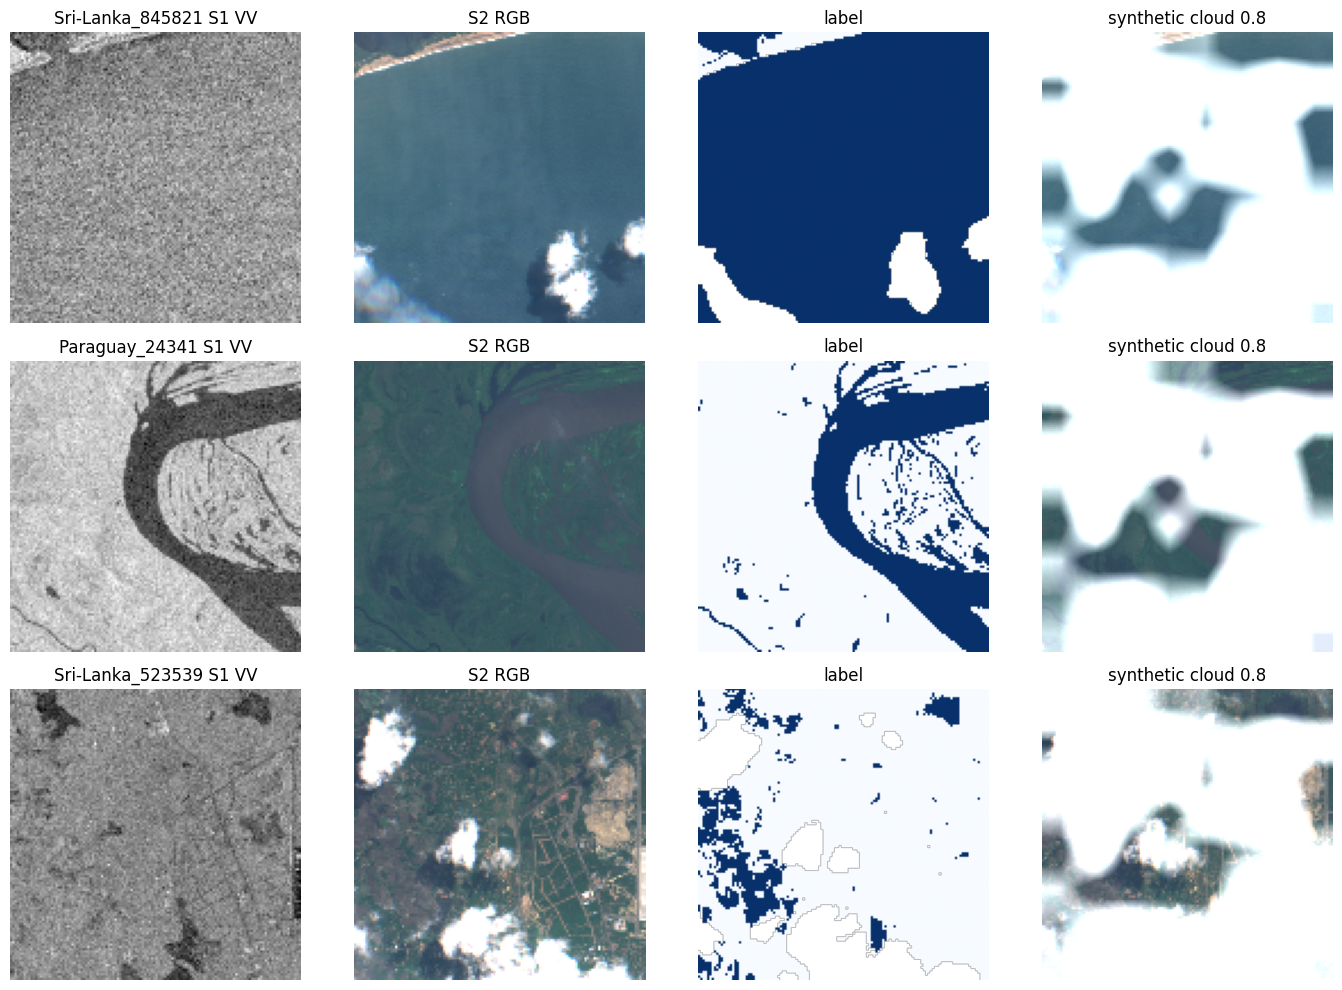

In [8]:
# 8.1 — label statistics and a visual
def split_stats(split):
    y = DATA[split]["y"]; valid = y != IGNORE_INDEX
    flood = (y == 1).sum((1, 2)); vcount = valid.sum((1, 2))
    return dict(split=split, chips=len(y), valid_px=int(valid.sum()), flood_px=int((y == 1).sum()),
                flood_frac=float((y == 1).sum() / max(valid.sum(), 1)),
                chips_with_flood=int((flood > 0).sum()), chips_without_flood=int((flood == 0).sum()),
                chips_fully_ignored=int((vcount == 0).sum()), ignored_frac=float(1 - valid.mean()))
stats_df = pd.DataFrame([split_stats(s) for s in DATA]); display(stats_df)
stats_df.to_csv(RESULTS_DIR/"evaluation"/"split_label_stats.csv", index=False)
assert (stats_df.flood_px > 0).all(), "a split without any flood pixels"

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
d = DATA["train"]; order = np.argsort(-(d["y"] == 1).sum((1, 2)))[[0, 20, 60]]
for r, i in enumerate(order):
    yy = d["y"][i]
    axes[r,0].imshow(d["s1"][i][0], cmap="gray"); axes[r,0].set_title(f"{d['ids'][i]} S1 VV")
    axes[r,1].imshow(np.clip(np.moveaxis(d["s2"][i][[3,2,1]],0,-1)*3.5,0,1)); axes[r,1].set_title("S2 RGB")
    axes[r,2].imshow(np.ma.masked_where(yy==IGNORE_INDEX, yy), vmin=0, vmax=1, cmap="Blues"); axes[r,2].set_title("label")
    rng = np.random.default_rng(0); cl = cloud_corrupt(d["s2"][i], 0.8, rng)
    axes[r,3].imshow(np.clip(np.moveaxis(cl[[3,2,1]],0,-1)*3.5,0,1)); axes[r,3].set_title("synthetic cloud 0.8")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(RESULTS_DIR/"figures"/"fig0_data_check.png", dpi=150); plt.show()

## 9. Model architectures
All networks share one `ConvBlock` (**GroupNorm** instead of the original BatchNorm — *changed on purpose*: with mixed availability states inside a batch, BatchNorm statistics would mix zeroed-modality and real samples, making a sample's output depend on its batch-mates; GroupNorm is per-sample and also stable at small batch sizes).

| Name | Inputs | Handles missing sensor? |
|---|---|---|
| `RadarUNet` (`SingleStreamUNet kind=radar`) | S1 (2 ch) | radar-only state only |
| `OpticalUNet` (`kind=optical`) | S2 (13 ch) | optical-only state only |
| `EarlyFusionUNet` (`kind=early`) | S1‖S2 (15 ch) concatenated | **No** — only the *both* state (a zero-filled missing sensor would be indistinguishable from real zeros) |
| `SensorAwareFusionUNet` (proposed) | S1, S2, availability `[radar, optical]` | all three |
| `SensorAwareFusionUNet(plain=True)` | S1, S2, availability used only to zero hidden inputs | trained with random sensor dropout; the *network is not told* which sensor is missing |

**Proposed model.** Two encoders (3 scales). At each scale `k`:
1. availability vector → learned embedding `e` (`Linear→ReLU→Linear`);
2. gate logits = `Conv1×1([radar_k, optical_k, e])`; logits of **unavailable sensors are set to −1e4 before the softmax** and the result multiplied by the availability mask ⇒ unavailable sensors get *exactly* zero weight and available weights sum to one;
3. the fusion input is `[radar_k·w_r, optical_k·w_o, ô_k·(1−a_opt)]` where `ô_k` is the **radar→optical feature head** output (a function of radar features only; active only when optical is missing);
4. fused features are modulated by FiLM(e) (γ,β initialised at 0 ⇒ identity), so the embedding influences features, not only the gate.

Hidden modalities are multiplied by their availability flag at the input, so outputs under a hidden sensor are *bit-identical* whatever data sit in that sensor's channels (tested below).

In [9]:
# 9.1 — architectures
STATES = {"both": (1.0, 1.0), "radar_only": (1.0, 0.0), "optical_only": (0.0, 1.0)}
ALL_STATES = list(STATES)

def _gn(c): return nn.GroupNorm(min(8, c), c)

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), _gn(cout), nn.ReLU(inplace=True),
                                   nn.Conv2d(cout, cout, 3, padding=1, bias=False), _gn(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class SingleStreamUNet(nn.Module):
    """kind: 'radar' (S1), 'optical' (S2) or 'early' (S1||S2 concatenation)."""
    def __init__(self, kind, base=16, s2_channels=13, drop_p=0.1):
        super().__init__()
        assert kind in ("radar", "optical", "early"); self.kind = kind
        cin = {"radar": 2, "optical": s2_channels, "early": 2 + s2_channels}[kind]
        b = base
        self.enc1, self.enc2, self.enc3 = ConvBlock(cin, b), ConvBlock(b, 2*b), ConvBlock(2*b, 4*b)
        self.pool = nn.MaxPool2d(2); self.drop = nn.Dropout2d(drop_p)
        self.up2, self.dec2 = nn.ConvTranspose2d(4*b, 2*b, 2, 2), ConvBlock(4*b, 2*b)
        self.up1, self.dec1 = nn.ConvTranspose2d(2*b, b, 2, 2), ConvBlock(2*b, b)
        self.out = nn.Conv2d(b, 1, 1)
    def forward(self, radar, optical, availability):
        if self.kind == "radar" and not bool((availability[:, 0] == 1).all()): raise ValueError("radar U-Net needs radar")
        if self.kind == "optical" and not bool((availability[:, 1] == 1).all()): raise ValueError("optical U-Net needs optical")
        if self.kind == "early" and not bool((availability == 1).all()):
            raise ValueError("EarlyFusionUNet cannot handle a missing sensor (state 'both' only)")
        x = {"radar": radar, "optical": optical, "early": torch.cat([radar, optical], 1)}[self.kind]
        a = self.enc1(x); b_ = self.enc2(self.pool(a)); c = self.drop(self.enc3(self.pool(b_)))
        z = self.drop(self.dec2(torch.cat([self.up2(c), b_], 1)))
        z = self.dec1(torch.cat([self.up1(z), a], 1))
        return self.out(z), {}

class SensorAwareFusionUNet(nn.Module):
    def __init__(self, base=16, s2_channels=13, use_embed=True, use_gate=True, use_opt_head=True,
                 plain=False, emb_dim=16, drop_p=0.1):
        super().__init__()
        self.plain = plain
        self.use_embed = use_embed and not plain
        self.use_gate = use_gate and not plain
        self.use_opt_head = use_opt_head and not plain
        b = base; ch = [b, 2*b, 4*b]; self.ch = ch
        self.r_enc = nn.ModuleList([ConvBlock(2, ch[0]), ConvBlock(ch[0], ch[1]), ConvBlock(ch[1], ch[2])])
        self.o_enc = nn.ModuleList([ConvBlock(s2_channels, ch[0]), ConvBlock(ch[0], ch[1]), ConvBlock(ch[1], ch[2])])
        self.pool = nn.MaxPool2d(2); self.drop = nn.Dropout2d(drop_p)
        if self.use_embed:
            self.avail_embed = nn.Sequential(nn.Linear(2, emb_dim), nn.ReLU(inplace=True), nn.Linear(emb_dim, emb_dim))
            self.film = nn.ModuleList([nn.Linear(emb_dim, 2*c) for c in ch])
            for m in self.film: nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)
        if self.use_gate:
            self.gates = nn.ModuleList([nn.Conv2d(2*c + (emb_dim if self.use_embed else 0), 2, 1) for c in ch])
        if self.use_opt_head:
            self.heads = nn.ModuleList([nn.Sequential(nn.Conv2d(c, c, 3, padding=1, bias=False), _gn(c),
                                                      nn.ReLU(inplace=True), nn.Conv2d(c, c, 1)) for c in ch])
        n_in = 3 if self.use_opt_head else 2
        self.fuse = nn.ModuleList([ConvBlock(n_in*c, c) for c in ch])
        self.up2, self.dec2 = nn.ConvTranspose2d(ch[2], ch[1], 2, 2), ConvBlock(2*ch[1], ch[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(ch[1], ch[0], 2, 2), ConvBlock(2*ch[0], ch[0])
        self.out = nn.Conv2d(ch[0], 1, 1)

    def optical_features(self, optical):
        """Teacher features for the radar->optical head (call under no_grad on CLEAN optical)."""
        feats, x = [], optical
        for k, enc in enumerate(self.o_enc):
            x = enc(x if k == 0 else self.pool(x)); feats.append(x)
        return feats

    def _fuse(self, k, r, o, o_hat, avail, emb):
        present = avail[:, :, None, None]                          # [B,2,1,1]
        bsz, _, h, wd = r.shape
        gate_w = None
        if self.plain:
            fused_in = torch.cat([r, o], 1)                        # not told which one is missing
        else:
            if self.use_gate:
                gin = [r, o] + ([emb[:, :, None, None].expand(-1, -1, h, wd)] if emb is not None else [])
                logits = self.gates[k](torch.cat(gin, 1)).masked_fill(present == 0, -1e4)
                gate_w = torch.softmax(logits.float(), 1).to(r.dtype)
            else:                                                  # ungated: equal weight over AVAILABLE sensors
                gate_w = (present / present.sum(1, keepdim=True)).expand(-1, -1, h, wd).to(r.dtype)
            gate_w = gate_w * present.to(gate_w.dtype)             # exact zero for unavailable sensors
            parts = [r * gate_w[:, 0:1], o * gate_w[:, 1:2]]
            if self.use_opt_head: parts.append(o_hat * (1 - present[:, 1:2]).to(r.dtype))
            fused_in = torch.cat(parts, 1)
        out = self.fuse[k](fused_in)
        if emb is not None:
            gamma, beta = self.film[k](emb).chunk(2, 1)
            out = out * (1 + gamma[:, :, None, None].to(out.dtype)) + beta[:, :, None, None].to(out.dtype)
        return out, gate_w

    def forward(self, radar, optical, availability):
        if availability.ndim != 2 or availability.shape[1] != 2: raise ValueError("availability must be [B,2]")
        if bool((availability.sum(1) < 1).any()): raise ValueError("at least one sensor must be available")
        availability = availability.to(radar.dtype)
        radar = radar * availability[:, 0].view(-1, 1, 1, 1)       # hidden modality -> exactly zero input
        optical = optical * availability[:, 1].view(-1, 1, 1, 1)
        emb = self.avail_embed(availability) if self.use_embed else None
        r, o, fused, gates, o_hats = radar, optical, [], [], []
        for k in range(3):
            r = self.r_enc[k](r if k == 0 else self.pool(r))
            o = self.o_enc[k](o if k == 0 else self.pool(o))
            o_hat = self.heads[k](r) if self.use_opt_head else None   # radar features ONLY -> no leakage
            f, g = self._fuse(k, r, o, o_hat, availability, emb)
            fused.append(f); gates.append(g); o_hats.append(o_hat)
        f1, f2, f3 = fused
        f3 = self.drop(f3)
        z = self.drop(self.dec2(torch.cat([self.up2(f3), f2], 1)))
        z = self.dec1(torch.cat([self.up1(z), f1], 1))
        return self.out(z), {"gates": gates, "o_hat": o_hats}

def count_parameters(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

# 9.2 — model registry (every experiment is a named spec; ablations reuse the same code path)
def _spec(arch, recipe, states, flags=None, **hp): return dict(arch=arch, recipe=recipe, states=states, flags=flags or {}, hp=hp)
SPECS = {
    "radar_unet":     _spec("radar",   "single", ["radar_only"]),
    "optical_unet":   _spec("optical", "single", ["optical_only"]),
    "early_fusion":   _spec("early",   "single", ["both"]),
    "dropout_fusion": _spec("fusion",  "dropout", ALL_STATES, flags=dict(plain=True)),
    "aware_fusion":   _spec("fusion",  "aware",   ALL_STATES),
    # ablations of the proposed model (one component removed at a time)
    "aware_no_consistency": _spec("fusion", "aware", ALL_STATES, lam_cons=0.0),
    "aware_no_embedding":   _spec("fusion", "aware", ALL_STATES, flags=dict(use_embed=False)),
    "aware_no_gate":        _spec("fusion", "aware", ALL_STATES, flags=dict(use_gate=False)),
    "aware_no_opthead":     _spec("fusion", "aware", ALL_STATES, flags=dict(use_opt_head=False), lam_head=0.0),
    "aware_no_calterm":     _spec("fusion", "aware", ALL_STATES, lam_cal=0.0),
}
for _w in (0.1, 1.0):   # consistency-weight sweep (0.0 == aware_no_consistency, default == aware_fusion)
    SPECS[f"aware_cons{_w}"] = _spec("fusion", "aware", ALL_STATES, lam_cons=_w)

def build_model(name, base=16, drop_p=0.1):
    sp = SPECS[name]
    if sp["arch"] in ("radar", "optical", "early"): return SingleStreamUNet(sp["arch"], base=base, drop_p=drop_p)
    return SensorAwareFusionUNet(base=base, drop_p=drop_p, **sp["flags"])

print({n: f"{count_parameters(build_model(n)):,}" for n in ["radar_unet", "optical_unet", "early_fusion", "dropout_fusion", "aware_fusion",
                                                           "aware_no_embedding", "aware_no_gate", "aware_no_opthead"]})

{'radar_unet': '117,217', 'optical_unet': '118,801', 'early_fusion': '119,089', 'dropout_fusion': '336,561', 'aware_fusion': '443,719', 'aware_no_embedding': '439,495', 'aware_no_gate': '443,169', 'aware_no_opthead': '341,239'}


In [10]:
# 9.3 — model self-tests (run on whatever device is active; every assertion is a real check)
def run_model_selftests():
    torch.manual_seed(0); B, H = 3, 64
    s1, s2 = torch.rand(B, 2, H, H), torch.rand(B, 13, H, H)
    s2_other = torch.rand(B, 13, H, H) * 5 + 1; s1_other = torch.rand(B, 2, H, H) * 5 + 1
    A = {k: torch.tensor(v).repeat(B, 1) for k, v in STATES.items()}
    for n in ["radar_unet", "optical_unet", "early_fusion", "dropout_fusion", "aware_fusion", "aware_no_embedding",
              "aware_no_gate", "aware_no_opthead"]:
        m = build_model(n).eval()
        for st in SPECS[n]["states"]:
            with torch.no_grad(): y, aux = m(s1, s2, A[st])
            assert y.shape == (B, 1, H, H) and torch.isfinite(y).all(), (n, st)
    # --- availability semantics of the proposed model ---
    m = build_model("aware_fusion").eval()
    with torch.no_grad():
        for st, (ar, ao) in STATES.items():
            y, aux = m(s1, s2, A[st])
            for g in aux["gates"]:
                assert torch.isfinite(g).all()
                assert torch.allclose(g.sum(1), torch.ones_like(g.sum(1)), atol=1e-5), "gate weights must sum to 1"
                assert (g[:, 0] == 0).all() if not ar else True
                assert (g[:, 1] == 0).all() if not ao else True       # unavailable => EXACT zero weight
        # radar-only output cannot depend on optical content; optical-only cannot depend on radar content
        ya, _ = m(s1, s2, A["radar_only"]);  yb, _ = m(s1, s2_other, A["radar_only"])
        assert torch.equal(ya, yb), "LEAK: radar-only output depends on optical data"
        ya, _ = m(s1, s2, A["optical_only"]); yb, _ = m(s1_other, s2, A["optical_only"])
        assert torch.equal(ya, yb), "LEAK: optical-only output depends on radar data"
        # each stream is actually used: changing the available sensor's data changes the output
        ya, _ = m(s1, s2, A["radar_only"]);  yb, _ = m(s1_other, s2, A["radar_only"]); assert not torch.equal(ya, yb)
        ya, _ = m(s1, s2, A["optical_only"]); yb, _ = m(s1, s2_other, A["optical_only"]); assert not torch.equal(ya, yb)
        ya, _ = m(s1, s2, A["both"]); yb, _ = m(s1_other, s2, A["both"]); yc, _ = m(s1, s2_other, A["both"])
        assert not torch.equal(ya, yb) and not torch.equal(ya, yc), "both-sensor mode should use both streams"
        # a hidden sensor is not the same as an observed zero image
        y_zero, _ = m(s1, torch.zeros_like(s2), A["both"]); y_hide, _ = m(s1, s2, A["radar_only"])
        assert not torch.equal(y_zero, y_hide)
    # plain dropout model: hidden modality is zeroed (no leak) but the network is not told which one
    mp = build_model("dropout_fusion").eval()
    with torch.no_grad():
        ya, _ = mp(s1, s2, A["radar_only"]); yb, _ = mp(s1, s2_other, A["radar_only"]); assert torch.equal(ya, yb)
    # unsupported states must raise
    for n, st in [("early_fusion", "radar_only"), ("radar_unet", "optical_only"), ("optical_unet", "radar_only")]:
        try: build_model(n).eval()(s1, s2, A[st]); raise AssertionError(f"{n} accepted {st}")
        except ValueError: pass
    # embedding is really used: perturbing its weights changes the output; unused-parameter check
    m = build_model("aware_fusion").eval(); y0, _ = m(s1, s2, A["both"])
    with torch.no_grad():
        for p in m.film.parameters(): p.add_(0.5)
    y1, _ = m(s1, s2, A["both"]); assert not torch.equal(y0, y1), "availability embedding has no effect"
    m = build_model("aware_fusion").train(); y, aux = m(s1, s2, A["radar_only"])
    (y.mean() + sum(h.mean() for h in aux["o_hat"])).backward()
    unused = [n for n, p in m.named_parameters() if p.grad is None]
    # in a radar-only forward the *optical encoder* is legitimately unused downstream (w_o = 0), so we only report
    print("params without grad in a radar-only pass (expected: optical-encoder/gate-free paths):", len(unused))
    print("MODEL SELF-TESTS PASSED")
run_model_selftests()

params without grad in a radar-only pass (expected: optical-encoder/gate-free paths): 0
MODEL SELF-TESTS PASSED


## 10. Loss functions
* `masked_bce_dice` — preserved (BCE + soft Dice on non-ignored pixels).
* `consistency_loss(student=radar-only, teacher=fused)` — MSE between probabilities with the **teacher detached**: the radar-only state is pulled toward the both-sensor state but the fused prediction is *not* pulled toward radar (the original symmetric version let radar drag the fused output). **Optical-only is not asked to imitate radar-only.**
* `brier_loss` — the calibration term (a proper scoring rule, penalises over/under-confidence). This is a *calibration surrogate*; it does not by itself make probabilities calibrated, and the ECE results should be read accordingly.
* `head_loss` — MSE between the radar→optical head's features and (detached) features the optical encoder produces for the **clean** optical image.

In [11]:
# 10.1 — losses
def masked_bce_dice(logits, target):
    logits = logits.float()[:, 0]; valid = target != IGNORE_INDEX
    if not bool(valid.any()): return logits.sum() * 0.0
    truth = (target == 1).float()[valid]; lv = logits[valid]
    bce = F.binary_cross_entropy_with_logits(lv, truth)
    p = torch.sigmoid(lv)
    dice = 1.0 - (2.0 * (p * truth).sum() + 1e-6) / (p.sum() + truth.sum() + 1e-6)
    return bce + dice

def brier_loss(logits, target):
    valid = target != IGNORE_INDEX
    if not bool(valid.any()): return logits.float().sum() * 0.0
    p = torch.sigmoid(logits.float()[:, 0])[valid]; t = (target == 1).float()[valid]
    return ((p - t) ** 2).mean()

def consistency_loss(student_logits, teacher_logits, target):
    valid = (target != IGNORE_INDEX).float()
    ps = torch.sigmoid(student_logits.float()[:, 0]); pt = torch.sigmoid(teacher_logits.detach().float()[:, 0])
    return (((ps - pt) ** 2) * valid).sum() / valid.sum().clamp_min(1.0)

def head_loss(o_hats, teachers):
    return sum(F.mse_loss(h.float(), t.detach().float()) for h, t in zip(o_hats, teachers)) / len(teachers)

def run_loss_selftests():
    y = torch.full((2, 8, 8), IGNORE_INDEX, dtype=torch.long); y[0, :4] = 1; y[0, 4:] = 0   # 2nd chip fully ignored
    perfect = torch.where(y[:, None] == 1, torch.tensor(20.0), torch.tensor(-20.0))
    assert masked_bce_dice(perfect, y) < 1e-3
    lg = torch.randn(2, 1, 8, 8, requires_grad=True); l = masked_bce_dice(lg, y); l.backward()
    assert torch.isfinite(l) and (lg.grad[1] == 0).all(), "ignored pixels must get zero gradient"
    assert masked_bce_dice(torch.randn(1, 1, 4, 4), torch.full((1, 4, 4), IGNORE_INDEX)) == 0
    a = torch.randn(2, 1, 8, 8, requires_grad=True); b = torch.randn(2, 1, 8, 8, requires_grad=True)
    consistency_loss(a, b, y).backward(); assert b.grad is None or (b.grad == 0).all(), "teacher must be detached"
    assert brier_loss(perfect, y) < 1e-6
    print("LOSS SELF-TESTS PASSED")
run_loss_selftests()

LOSS SELF-TESTS PASSED


## 11. Training configuration
Three presets. **Only `RUN_MODE` (Section 2) switches them.** The preset is stored in every checkpoint's compatibility record, so a checkpoint from one preset is never silently reused by another (and `smoke` writes to its own folder).

| Preset | Chips | Epochs | Seeds | Batch | Purpose |
|---|---|---|---|---|---|
| `smoke` | 24/16/12/8 (explicitly truncated) | 2 | 1 | 8 | does the pipeline run end-to-end? **not a result** |
| `one_day` | official full splits | 40 | 3 | 16 | priority experiments |
| `long` | official full splits | 100 | 5 | 16 | final study |

*Compute (estimates, not measurements — time your first epoch):* with all data in RAM the model is tiny (≈0.12–0.5 M parameters), so one epoch should take seconds on a T4; the aware recipe costs ≈3× a single-state step. If `one_day` is too slow, reduce `ABLATION_SEEDS` first, never the chips.

**Calibration split.** The official validation chips are split deterministically (per event, by hash) into `val_sel` (model selection/early stopping) and `val_cal` (temperature scaling + thresholds). Thresholds are therefore never chosen on data used for model selection, nor on test.

In [12]:
# 11.1 — configuration
CFG_PRESETS = {
  "smoke":   dict(epochs=2,   seeds=[0],             ablation_seeds=[0],       batch=8,  lr=3e-4, n_boot=100),
  "one_day": dict(epochs=40,  seeds=[0, 1, 2],       ablation_seeds=[0, 1, 2], batch=16, lr=3e-4, n_boot=1000),
  "long":    dict(epochs=100, seeds=[0, 1, 2, 3, 4], ablation_seeds=[0, 1, 2], batch=16, lr=3e-4, n_boot=2000),
}
CFG = dict(CFG_PRESETS[RUN_MODE])
CFG.update(
    base=16, drop_p=0.1, weight_decay=1e-4, grad_clip=1.0,
    cloud_max_train=0.70,                          # severity ~ U(0, 0.7) per training sample (all models that see optical)
    lam_cons=0.5, lam_head=0.1, lam_cal=0.5, w_state=dict(both=1.0, radar_only=1.0, optical_only=1.0),
    dropout_probs=dict(both=0.4, radar_only=0.3, optical_only=0.3),   # plain sensor-dropout baseline
    val_severities=(0.0, 0.5),                     # model-selection validation: clean + cloudy optical
    cal_fraction=0.6,                              # share of official-val chips used for CALIBRATION
    target_miss=0.10, alphas=(0.05, 0.10, 0.20),
    eval_cloud_seed=12345, eval_severities=(0.0, 0.3, 0.6, 0.9, 1.0),
    num_workers=0, mc_samples=20 if RUN_MODE != "smoke" else 4, compile=False,
)
print(RUN_MODE, json.dumps({k: v for k, v in CFG.items() if k in ("epochs", "seeds", "batch", "lr", "target_miss")}))
EVAL_CLOUD_SEED = CFG["eval_cloud_seed"]

# 11.2 — carve model-selection / calibration chips out of the OFFICIAL validation split (event-stratified, deterministic)
def carve_val(val_ids, cal_fraction):
    by_event = defaultdict(list)
    for c in val_ids: by_event[event_of(c)].append(c)
    sel, cal = [], []
    for ev, cs in sorted(by_event.items()):
        cs = sorted(cs, key=lambda c: stable_seed("calsplit|" + c)); n_sel = int(round(len(cs) * (1 - cal_fraction)))
        sel += cs[:n_sel]; cal += cs[n_sel:]
    return sorted(sel), sorted(cal)

def subset_split(parent, ids):
    d = DATA[parent]; pos = {c: i for i, c in enumerate(d["ids"])}; ix = [pos[c] for c in ids]
    return dict(ids=list(ids), s1=d["s1"][ix], s2=d["s2"][ix], y=d["y"][ix], area=d["area"][ix])

_sel, _cal = carve_val(DATA["val"]["ids"], CFG["cal_fraction"])
assert not (set(_sel) & set(_cal)) and set(_sel) | set(_cal) == set(DATA["val"]["ids"])
DATA["val_sel"], DATA["val_cal"] = subset_split("val", _sel), subset_split("val", _cal)
for k in ("train", "val_sel", "val_cal", "test", "bolivia"):
    assert len(DATA[k]["ids"]) > 0
SPLIT_IDS = {k: DATA[k]["ids"] for k in ("train", "val_sel", "val_cal", "test", "bolivia")}
all_ids = [c for v in SPLIT_IDS.values() for c in v]; assert len(all_ids) == len(set(all_ids)), "leakage between splits"
SPLIT_HASH = hashlib.sha256(json.dumps(SPLIT_IDS, sort_keys=True).encode()).hexdigest()[:16]
print({k: len(v) for k, v in SPLIT_IDS.items()}, "| split hash", SPLIT_HASH)
pd.DataFrame([(k, c) for k, v in SPLIT_IDS.items() for c in v], columns=["split", "chip_id"]).to_csv(
    RESULTS_DIR/"config"/f"splits_{RUN_MODE}.csv", index=False)

one_day {"epochs": 40, "seeds": [0, 1, 2], "batch": 16, "lr": 0.0003, "target_miss": 0.1}
{'train': 252, 'val_sel': 36, 'val_cal': 53, 'test': 90, 'bolivia': 15} | split hash 1b33f76b246200ed


## 12. Model training (+ 13. checkpoint management)
`train_run(name, seed)` is the **single** training routine used by every baseline, the proposed model and every ablation.

* **Recipes** — `single` (one-sensor or early-fusion baseline, same loss/optimiser/cloud augmentation), `dropout` (plain random per-sample sensor dropout, segmentation loss only), `aware` (every step forwards the batch under all three availability states: both, radar-only, optical-only; segmentation loss for each; radar→fused consistency; head loss; Brier term).
* Cloud corruption (GPU, severity ~ U(0, 0.7)) and flips are re-drawn every step/epoch — nothing stochastic is cached.
* AMP on CUDA; AdamW; cosine LR; gradient clipping. `torch.compile` is **off** by default: with ≈15 optimiser steps per epoch the compile time would exceed any saving (not measured — flip `CFG["compile"]` if you want to test).
* **Checkpoints** (`results/checkpoints/<mode>/<name>_s<seed>_{last,best}.pt`): model, optimiser, scheduler, AMP scaler, epoch, best validation loss, history, RNG states, seed, config and a **compatibility record** (spec, hyper-parameters, preprocessing, split hash, parameter count). A finished compatible run is reused instead of retrained; an unfinished compatible run is resumed; an incompatible one is moved to `*.stale` and retrained. Model selection uses `val_sel` only.

In [13]:
# 12.1 — validation loss on val_sel (deterministic cloud corruption), states = those the model is trained for
_VALSEL_CACHE = {}
def _valsel_tensors(severity):
    if severity not in _VALSEL_CACHE:
        d = DATA["val_sel"]
        s2 = d["s2"] if severity <= 0 else np.stack([eval_cloud_s2(d["s2"][i], d["ids"][i], severity, EVAL_CLOUD_SEED) for i in range(len(d["ids"]))])
        _VALSEL_CACHE[severity] = (torch.from_numpy(d["s1"]), torch.from_numpy(np.ascontiguousarray(s2)),
                                   torch.from_numpy(d["y"]).long())
    return _VALSEL_CACHE[severity]

def avail_tensor(state, n):
    return torch.tensor(STATES[state], device=DEVICE).repeat(n, 1)

@torch.no_grad()
def evaluate_val_loss(model, name, bs=32):
    model.eval(); sp = SPECS[name]; losses = []
    for st in sp["states"]:
        sevs = CFG["val_severities"] if st != "radar_only" else (0.0,)      # radar-only is independent of optical
        for sev in sevs:
            s1, s2, y = _valsel_tensors(sev); tot, cnt = 0.0, 0
            for i in range(0, len(y), bs):
                a, b, t = s1[i:i+bs].to(DEVICE), s2[i:i+bs].to(DEVICE), y[i:i+bs].to(DEVICE)
                with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                    lg, _ = model(a, b, avail_tensor(st, len(t)))
                n_valid = int((t != IGNORE_INDEX).sum());
                if n_valid == 0: continue
                l = masked_bce_dice(lg, t); assert torch.isfinite(l), "non-finite validation loss"
                tot += float(l) * n_valid; cnt += n_valid
            assert cnt > 0, "val_sel has no valid pixels"
            losses.append(tot / cnt)
    return float(np.mean(losses))

# 12.2 — one optimisation step per recipe
def training_step(model, name, s1, s2, y, cfg):
    sp = SPECS[name]; hp = {**dict(lam_cons=cfg["lam_cons"], lam_head=cfg["lam_head"], lam_cal=cfg["lam_cal"]), **sp["hp"]}
    B = s1.size(0)
    sev = torch.rand(B, device=s1.device) * cfg["cloud_max_train"]
    s2c = cloud_corrupt_batch_torch(s2, sev)                                  # stochastic, new every step
    parts = {}
    if sp["recipe"] == "single":
        st = sp["states"][0]; lg, _ = model(s1, s2c, avail_tensor(st, B)); loss = masked_bce_dice(lg, y)
        parts[f"seg_{st}"] = loss.detach()
    elif sp["recipe"] == "dropout":
        p = cfg["dropout_probs"]; u = torch.rand(B, device=s1.device)
        both = u < p["both"]; rad = (u >= p["both"]) & (u < p["both"] + p["radar_only"])
        av = torch.stack([(both | rad).float(), (~rad).float()], 1)          # both->[1,1]; radar->[1,0]; optical->[0,1]
        lg, _ = model(s1, s2c, av); loss = masked_bce_dice(lg, y); parts["seg_random_state"] = loss.detach()
    else:  # aware
        out = {st: model(s1, s2c, avail_tensor(st, B)) for st in ALL_STATES}
        loss = 0.0
        for st in ALL_STATES:
            l = masked_bce_dice(out[st][0], y); parts[f"seg_{st}"] = l.detach(); loss = loss + cfg["w_state"][st] * l
        if hp["lam_cons"] > 0:
            lc = consistency_loss(out["radar_only"][0], out["both"][0], y); parts["cons"] = lc.detach(); loss = loss + hp["lam_cons"] * lc
        if hp["lam_head"] > 0 and model.use_opt_head:
            with torch.no_grad(): teach = model.optical_features(s2)           # CLEAN optical features, no grad
            lh = head_loss(out["radar_only"][1]["o_hat"], teach); parts["head"] = lh.detach(); loss = loss + hp["lam_head"] * lh
        if hp["lam_cal"] > 0:
            lb = sum(brier_loss(out[st][0], y) for st in ALL_STATES) / 3; parts["brier"] = lb.detach(); loss = loss + hp["lam_cal"] * lb
    return loss, parts

# 13.1 — compatibility record + checkpoint helpers
def make_compat(name, seed, cfg):
    sp = SPECS[name]
    hp = {**dict(lam_cons=cfg["lam_cons"], lam_head=cfg["lam_head"], lam_cal=cfg["lam_cal"]), **sp["hp"]} if sp["recipe"] == "aware" else {}
    return json.loads(json.dumps(dict(
        name=name, spec=sp, seed=seed, hp_resolved=hp, run_mode=RUN_MODE,
        train={k: cfg[k] for k in ("epochs", "lr", "batch", "weight_decay", "grad_clip", "cloud_max_train", "base", "drop_p",
                                   "w_state", "dropout_probs", "val_severities", "eval_cloud_seed")},
        preproc=PREPROC, split_hash=SPLIT_HASH, n_params=count_parameters(build_model(name, cfg["base"], cfg["drop_p"])),
    ), default=str))

CK_DIR = RESULTS_DIR / "checkpoints" / RUN_MODE; CK_DIR.mkdir(parents=True, exist_ok=True)
def ck_paths(name, seed): return CK_DIR / f"{name}_s{seed}_last.pt", CK_DIR / f"{name}_s{seed}_best.pt"

def rng_state():
    return dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)
def set_rng_state(s):
    random.setstate(s["py"]); np.random.set_state(s["np"]); torch.set_rng_state(s["torch"])
    if s["cuda"] is not None and torch.cuda.is_available(): torch.cuda.set_rng_state_all(s["cuda"])

def train_run(name, seed, cfg=CFG, force=False, verbose=True):
    """Train (or reuse/resume) one model. Returns (model on DEVICE in eval mode, history DataFrame, status)."""
    compat = make_compat(name, seed, cfg); last_p, best_p = ck_paths(name, seed)
    model = build_model(name, cfg["base"], cfg["drop_p"]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    seed_everything(seed); start_epoch, best_val, best_epoch, history, status = 1, float("inf"), 0, [], "trained_from_scratch"
    if last_p.exists() and not force:
        try:
            ck = torch.load(last_p, map_location="cpu", weights_only=False)
        except Exception as e:
            print(f"[ckpt] {last_p.name} unreadable ({type(e).__name__}); retraining"); ck = None
        if ck is not None and ck.get("compat") == compat:
            if ck["finished"] and best_p.exists():
                bk = torch.load(best_p, map_location="cpu", weights_only=False)
                if bk.get("compat") == compat:
                    model.load_state_dict(bk["model"]); model.eval()
                    if verbose: print(f"[ckpt] REUSED finished run {name} s{seed} (best epoch {ck['best_epoch']}, val {ck['best_val']:.4f})")
                    return model, pd.DataFrame(ck["history"]), "reused"
            elif not ck["finished"]:
                model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
                scaler.load_state_dict(ck["scaler"]); set_rng_state(ck["rng"])
                start_epoch, best_val, best_epoch, history = ck["epoch"] + 1, ck["best_val"], ck["best_epoch"], ck["history"]
                status = f"resumed_from_epoch_{ck['epoch']}"
                if verbose: print(f"[ckpt] RESUMING {name} s{seed} at epoch {start_epoch}")
        elif ck is not None:
            diff = [k for k in compat if ck.get("compat", {}).get(k) != compat[k]]
            print(f"[ckpt] incompatible checkpoint for {name} s{seed} (differs in {diff}); moved to .stale, retraining")
            last_p.replace(last_p.with_suffix(".stale")); best_p.exists() and best_p.replace(best_p.with_suffix(".stale"))
    loader = make_loader(FloodArrayDataset("train", augment=True), cfg["batch"], True, cfg["num_workers"], seed)
    train_model = torch.compile(model) if cfg["compile"] else model
    for epoch in range(start_epoch, cfg["epochs"] + 1):
        t0 = time.perf_counter(); model.train(); acc, n_b = defaultdict(float), 0
        for s1, s2, y, _ in loader:
            s1, s2, y = s1.to(DEVICE, non_blocking=True), s2.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                loss, parts = training_step(train_model, name, s1, s2, y, cfg)
            if not torch.isfinite(loss): raise FloatingPointError(f"non-finite loss {name} s{seed} epoch {epoch}")
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            scaler.step(opt); scaler.update()
            acc["train_loss"] += float(loss.detach()); n_b += 1
            for k, v in parts.items(): acc[k] += float(v)
        sched.step(); vl = evaluate_val_loss(model, name)
        rec = {"epoch": epoch, "val_loss": vl, "seconds": time.perf_counter() - t0, **{k: v / n_b for k, v in acc.items()}}
        history.append(rec)
        if vl < best_val:
            best_val, best_epoch = vl, epoch
            torch.save(dict(model=model.state_dict(), epoch=epoch, compat=compat), best_p)
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state_dict(),
                        epoch=epoch, best_val=best_val, best_epoch=best_epoch, history=history, rng=rng_state(),
                        seed=seed, compat=compat, finished=False), last_p)
        if verbose and (epoch % 5 == 0 or epoch == start_epoch or epoch == cfg["epochs"]):
            print(f"{name} s{seed} ep{epoch:3d} train {rec['train_loss']:.3f} val {vl:.3f} ({rec['seconds']:.1f}s)")
    ck = torch.load(last_p, map_location="cpu", weights_only=False); ck["finished"] = True; torch.save(ck, last_p)
    bk = torch.load(best_p, map_location="cpu", weights_only=False); model.load_state_dict(bk["model"]); model.eval()
    hist = pd.DataFrame(history); hist.insert(0, "model", name); hist.insert(1, "seed", seed)
    if cfg.get("write_history", True): hist.to_csv(RESULTS_DIR/"history"/f"{RUN_MODE}_{name}_s{seed}.csv", index=False)
    return model, pd.DataFrame(history), status

TRAINED = {}   # (name, seed) -> model (eval, on DEVICE)
def get_model(name, seed):
    if (name, seed) not in TRAINED:
        TRAINED[(name, seed)] = train_run(name, seed)[0]
    return TRAINED[(name, seed)]

In [14]:
# 12.3 — checkpoint save/reload/resume/compat test + tiny end-to-end training test on 1 epoch (uses real data, a throw-away dir)
def run_checkpoint_selftest():
    global CK_DIR
    real_dir, real_cfg = CK_DIR, dict(CFG)
    CK_DIR = RESULTS_DIR / "checkpoints" / "_selftest"; shutil.rmtree(CK_DIR, ignore_errors=True); CK_DIR.mkdir(parents=True)
    try:
        c = dict(CFG, epochs=2, batch=8, write_history=False)
        m1, h1, st1 = train_run("aware_fusion", 0, c, verbose=False); assert st1 == "trained_from_scratch" and len(h1) == 2
        m2, h2, st2 = train_run("aware_fusion", 0, c, verbose=False); assert st2 == "reused"
        for (k, a), (_, b) in zip(m1.state_dict().items(), m2.state_dict().items()): assert torch.equal(a.cpu(), b.cpu()), k
        # compatibility: changing epochs must NOT reuse
        c3 = dict(c, epochs=3); m3, h3, st3 = train_run("aware_fusion", 0, c3, verbose=False); assert st3 == "trained_from_scratch"
        # resume: mark the 3-epoch run unfinished and rewind to epoch 2
        lp, bp = ck_paths("aware_fusion", 0); ck = torch.load(lp, map_location="cpu", weights_only=False)
        ck["finished"] = False; ck["epoch"] = 2; ck["history"] = ck["history"][:2]; torch.save(ck, lp)
        m4, h4, st4 = train_run("aware_fusion", 0, c3, verbose=False); assert st4.startswith("resumed") and len(h4) == 3, st4
        # every recipe runs one epoch and produces finite val loss
        for n in ["radar_unet", "optical_unet", "early_fusion", "dropout_fusion", "aware_no_embedding", "aware_no_gate", "aware_no_opthead"]:
            _, h, _ = train_run(n, 0, dict(c, epochs=1), verbose=False); assert np.isfinite(h["val_loss"]).all(), n
        print("CHECKPOINT / RECIPE SELF-TEST PASSED")
    finally:
        shutil.rmtree(CK_DIR, ignore_errors=True); CK_DIR = real_dir
run_checkpoint_selftest()

[ckpt] incompatible checkpoint for aware_fusion s0 (differs in ['train']); moved to .stale, retraining
CHECKPOINT / RECIPE SELF-TEST PASSED


In [15]:
# 12.4 — TRAIN EVERYTHING (finished compatible checkpoints are reused automatically; interrupted runs resume)
MAIN_MODELS = ["radar_unet", "optical_unet", "early_fusion", "dropout_fusion", "aware_fusion"]
ABLATION_MODELS = ["aware_no_consistency", "aware_no_embedding", "aware_no_gate", "aware_no_opthead"]
EXTRA_ABLATIONS = ["aware_no_calterm", "aware_cons0.1", "aware_cons1.0"]      # optional (RUN_EXTRA_ABLATIONS)
RUN_ABLATIONS, RUN_EXTRA_ABLATIONS = True, False

train_log = []
def train_all(names, seeds):
    for name in names:
        for seed in seeds:
            t0 = time.perf_counter(); model, hist, status = train_run(name, seed); TRAINED[(name, seed)] = model
            train_log.append(dict(model=name, seed=seed, status=status, epochs_logged=len(hist),
                                  best_val=float(hist["val_loss"].min()) if len(hist) else np.nan,
                                  best_epoch=int(hist.loc[hist["val_loss"].idxmin(), "epoch"]) if len(hist) else -1,
                                  wall_s=time.perf_counter() - t0, params=count_parameters(model)))
train_all(MAIN_MODELS, CFG["seeds"])
if RUN_ABLATIONS: train_all(ABLATION_MODELS, CFG["ablation_seeds"])
if RUN_EXTRA_ABLATIONS: train_all(EXTRA_ABLATIONS, CFG["ablation_seeds"])
train_df = pd.DataFrame(train_log); display(train_df)
train_df.to_csv(RESULTS_DIR/"history"/f"training_summary_{RUN_MODE}.csv", index=False)

radar_unet s0 ep  1 train 1.313 val 1.194 (0.9s)
radar_unet s0 ep  5 train 1.086 val 1.025 (0.7s)
radar_unet s0 ep 10 train 1.004 val 0.940 (0.7s)
radar_unet s0 ep 15 train 0.924 val 0.841 (0.7s)
radar_unet s0 ep 20 train 0.873 val 0.794 (0.7s)
radar_unet s0 ep 25 train 0.847 val 0.761 (0.6s)
radar_unet s0 ep 30 train 0.819 val 0.737 (0.7s)
radar_unet s0 ep 35 train 0.804 val 0.738 (0.7s)
radar_unet s0 ep 40 train 0.812 val 0.733 (0.7s)
radar_unet s1 ep  1 train 1.313 val 1.190 (0.7s)
radar_unet s1 ep  5 train 1.088 val 1.027 (0.7s)
radar_unet s1 ep 10 train 0.998 val 0.918 (0.7s)
radar_unet s1 ep 15 train 0.933 val 0.888 (0.7s)
radar_unet s1 ep 20 train 0.898 val 0.810 (0.7s)
radar_unet s1 ep 25 train 0.858 val 0.779 (0.7s)
radar_unet s1 ep 30 train 0.843 val 0.753 (0.7s)
radar_unet s1 ep 35 train 0.816 val 0.738 (0.7s)
radar_unet s1 ep 40 train 0.811 val 0.739 (0.7s)
radar_unet s2 ep  1 train 1.227 val 1.102 (0.6s)
radar_unet s2 ep  5 train 0.973 val 0.895 (0.6s)
radar_unet s2 ep 10 

,model,seed,status,epochs_logged,best_val,best_epoch,wall_s,params
0,radar_unet,0,trained_from_scratch,40,0.732182,38,27.916750,117217
1,radar_unet,1,trained_from_scratch,40,0.738044,35,27.965712,117217
2,radar_unet,2,trained_from_scratch,40,0.652965,37,27.334007,117217
3,optical_unet,0,trained_from_scratch,40,0.619833,37,28.776904,118801
4,optical_unet,1,trained_from_scratch,40,0.740830,40,29.497500,118801
5,optical_unet,2,trained_from_scratch,40,0.645089,40,29.325353,118801
6,early_fusion,0,trained_from_scratch,40,0.619316,40,28.941501,119089
7,early_fusion,1,trained_from_scratch,40,0.665912,40,29.317942,119089
8,early_fusion,2,trained_from_scratch,40,0.821624,40,28.989697,119089
9,dropout_fusion,0,trained_from_scratch,40,0.818784,40,50.095442,336561


## 14. Calibration of the missed-flood rate (central contribution)
### 14.1 Metrics and probability-calibration utilities
Pure NumPy, chip-resolved: every metric is first computed **per chip** (TP/FP/FN/TN counts, calibration-bin sums), so pooled numbers, per-chip numbers, and **chip-level bootstrap confidence intervals** all derive from the same arrays. Only pixels whose label is not "ignore" count.

Definitions used throughout
* pooled miss rate = ΣFN / Σ(TP+FN); **chip-macro miss rate** = mean over chips that contain ≥1 flood pixel of FN_i/(TP_i+FN_i). *Chips with no flood pixels have an undefined miss rate and are excluded from miss-rate statistics*; they are still counted for false alarms (`fp_px_on_noflood_chips`).
* false-alarm rate = FP/(FP+TN); false-positive pixels (count) always reported.
* **Approximate** false-alarm area: `Σ_i FP_i × area_per_128px_cell_i` where the cell area comes from the raster transform and the 512→128 resize (Section 5), spherical-earth approximation for EPSG:4326, flagged `approx`.
* ECE: 15 equal-width bins over pooled valid pixels (dominated by the large background class; read together with Brier and the reliability diagram).

In [18]:
# [PURE-NUMPY] 14.1 — chip-level counts, pooled/macro metrics, bootstrap, ECE/Brier, temperature scaling
IGNORE_INDEX = 255
def sigmoid_np(x): return 1.0 / (1.0 + np.exp(-np.clip(x, -50, 50)))
def logit_np(p, eps=1e-6): p = np.clip(p, eps, 1 - eps); return np.log(p / (1 - p))

def chip_counts(prob, y, thr):
    """prob [N,H,W] float, y [N,H,W] uint8 (0/1/255). Returns dict of per-chip count arrays."""
    valid = y != IGNORE_INDEX; truth = (y == 1); pred = prob >= thr
    ax = (1, 2)
    return dict(tp=(pred & truth).sum(ax), fp=(pred & ~truth & valid).sum(ax),
                fn=(~pred & truth).sum(ax), tn=(~pred & ~truth & valid).sum(ax))

def _safe(a, b): return a / np.maximum(b, 1)

def metrics_from_counts(c, idx=None):
    g = (lambda k: c[k].sum()) if idx is None else (lambda k: c[k][idx].sum())
    tp, fp, fn, tn = g("tp"), g("fp"), g("fn"), g("tn")
    return dict(IoU=_safe(tp, tp + fp + fn), F1=_safe(2 * tp, 2 * tp + fp + fn), precision=_safe(tp, tp + fp),
                recall=_safe(tp, tp + fn), miss_rate_pooled=_safe(fn, tp + fn), false_alarm_rate=_safe(fp, fp + tn),
                TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn))

def macro_miss(c):
    flood = (c["tp"] + c["fn"]) > 0
    if not flood.any(): return float("nan")
    return float((c["fn"][flood] / (c["tp"][flood] + c["fn"][flood])).mean())

def per_chip_table(c, ids, area_m2):
    df = pd.DataFrame({"chip_id": ids, **{k: c[k] for k in ("tp", "fp", "fn", "tn")}})
    df["has_flood"] = (df.tp + df.fn) > 0
    df["IoU"] = _safe(df.tp, df.tp + df.fp + df.fn); df["miss_rate"] = np.where(df.has_flood, df.fn / np.maximum(df.tp + df.fn, 1), np.nan)
    df["false_alarm_rate"] = _safe(df.fp, df.fp + df.tn); df["fp_area_km2_approx"] = df.fp * np.asarray(area_m2) / 1e6
    return df

def bootstrap_ci(c, n_boot=1000, seed=0):
    """Chip-level bootstrap (chips resampled with replacement) -> 95% percentile CIs."""
    n = len(c["tp"]); rng = np.random.default_rng(seed); idx = rng.integers(0, n, size=(n_boot, n))
    S = {k: c[k][idx].sum(1) for k in ("tp", "fp", "fn", "tn")}
    flood = ((c["tp"] + c["fn"]) > 0).astype(float); mchip = np.where(flood > 0, c["fn"] / np.maximum(c["tp"] + c["fn"], 1), 0.0)
    nf = flood[idx].sum(1); macro = np.where(nf > 0, (mchip * flood)[idx].sum(1) / np.maximum(nf, 1), np.nan)
    stats = dict(IoU=_safe(S["tp"], S["tp"] + S["fp"] + S["fn"]), F1=_safe(2 * S["tp"], 2 * S["tp"] + S["fp"] + S["fn"]),
                 miss_rate_pooled=_safe(S["fn"], S["tp"] + S["fn"]), miss_rate_chip_macro=macro,
                 false_alarm_rate=_safe(S["fp"], S["fp"] + S["tn"]), FP=S["fp"].astype(float))
    return {k: (float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))) for k, v in stats.items()}

K_BINS = 15
def bin_stats(prob, y, k=K_BINS):
    """Per-chip calibration-bin sums: n[N,K], conf_sum[N,K], acc_sum[N,K], sqerr[N], nvalid[N]."""
    N = len(prob); n = np.zeros((N, k)); cs = np.zeros((N, k)); ac = np.zeros((N, k)); se = np.zeros(N); nv = np.zeros(N)
    for i in range(N):
        v = y[i] != IGNORE_INDEX; p = prob[i][v].astype(np.float64); t = (y[i][v] == 1).astype(np.float64)
        b = np.minimum((p * k).astype(int), k - 1)
        n[i] = np.bincount(b, minlength=k); cs[i] = np.bincount(b, weights=p, minlength=k); ac[i] = np.bincount(b, weights=t, minlength=k)
        se[i] = ((p - t) ** 2).sum(); nv[i] = v.sum()
    return dict(n=n, conf=cs, acc=ac, sqerr=se, nvalid=nv)

def ece_from_bins(bs, idx=None):
    sl = slice(None) if idx is None else idx
    n, cf, ac = bs["n"][sl].sum(0), bs["conf"][sl].sum(0), bs["acc"][sl].sum(0)
    return float(np.abs(ac - cf).sum() / max(n.sum(), 1))
def brier_from_bins(bs, idx=None):
    sl = slice(None) if idx is None else idx
    return float(bs["sqerr"][sl].sum() / max(bs["nvalid"][sl].sum(), 1))

def fit_temperature(logits, y, max_px=2_000_000, seed=0):
    """Single scalar T minimising NLL on valid pixels (grid search -> deterministic, monotone => ranking unchanged)."""
    v = y != IGNORE_INDEX; L = logits[v].astype(np.float64); t = (y[v] == 1).astype(np.float64)
    if L.size > max_px: s = np.random.default_rng(seed).choice(L.size, max_px, replace=False); L, t = L[s], t[s]
    grid = np.exp(np.linspace(np.log(0.2), np.log(5.0), 161))
    nll = [np.mean(np.logaddexp(0, L / T) - t * (L / T)) for T in grid]
    return float(grid[int(np.argmin(nll))])

### 14.2 Threshold selection: three clearly separated procedures
All use **`val_cal` only** (never test, never `val_sel`, never train). Prediction rule: *flood if p ≥ t*; missed-flood loss is non-decreasing in `t`, so feasible thresholds form a prefix and we return the **largest feasible `t`** (fewest false alarms).

1. **`crc_chip` — chip-level conformal risk control (Angelopoulos et al., 2022, with B = 1).**
   Loss for calibration chip *i* containing flood: `L_i(t) = FN_i(t)/P_i ∈ [0,1]`, non-increasing in `λ = 1−t`. With `n` flood-containing calibration chips, choose
   `λ̂ = inf{ λ : n/(n+1)·R̂_n(λ) + 1/(n+1) ≤ α }`, `R̂_n(λ)=mean_i L_i`.
   **Guarantee:** if the `n` calibration chips and a new flood-containing chip are exchangeable and the model is fixed independently of them, then `E[L_{n+1}(λ̂)] ≤ α` — the *expected per-chip miss fraction*, averaged over the draw of calibration set and test chip.
   **What it is not:** not a per-pixel, per-image, or per-event guarantee; not a high-probability bound for one calibration draw; not pooled-pixel (large chips do not get more weight); not valid for no-flood chips (their miss fraction is undefined — they are excluded, so the statement is *conditional on the chip containing flood*). **Assumption risk:** chips from the same flood event are spatially correlated and the official split is chip-random across events, so exchangeability within an event is approximate; held-out Bolivia is a genuine distribution shift where the guarantee is **not** expected to hold. With `n ≈ 30–40` the finite-sample term `1/(n+1)` already costs ≈ 2.5–3 percentage points of α.
2. **`pixel_empirical`** — the original approach: largest `t` with pooled calibration miss ≤ α. **No guarantee of any kind**, shown for comparison.
3. **`global_*`** — one threshold shared by all availability states (calibration chips of all states pooled), used for the "per-state vs global threshold" ablation.

Temperature scaling is monotone ⇒ it **cannot change the binary map** once thresholds are re-selected after it; it only changes Brier/ECE. It provides **no** missed-flood guarantee.

In [19]:
# [PURE-NUMPY] 14.2 — threshold selection procedures
THR_GRID = np.unique(np.concatenate([[0.0], np.logspace(-6, -2, 41), np.linspace(0.0, 1.0, 1001), 1 - np.logspace(-4, -2, 11)]))
THR_GRID = THR_GRID[(THR_GRID >= 0) & (THR_GRID <= 1)]

def chip_miss_matrix(prob, y, grid=THR_GRID):
    """[n_flood_chips, G] per-chip miss fraction at every grid threshold, plus the chip indices used."""
    rows, used = [], []
    for i in range(len(prob)):
        pos = prob[i][y[i] == 1]
        if pos.size == 0: continue                                       # no-flood chip: miss rate undefined -> excluded
        rows.append(np.searchsorted(np.sort(pos), grid, side="left") / pos.size); used.append(i)
    return (np.array(rows) if rows else np.zeros((0, len(grid)))), used

def crc_threshold(prob, y, alpha, grid=THR_GRID):
    """Chip-level conformal risk control, B=1. Returns dict(threshold, feasible, n_flood_chips, risk_hat, bound)."""
    M, used = chip_miss_matrix(prob, y, grid); n = M.shape[0]
    if n == 0: return dict(threshold=0.0, feasible=False, n_flood_chips=0, risk_hat=np.nan, bound=np.nan)
    adj = (n / (n + 1.0)) * M.mean(0) + 1.0 / (n + 1.0)                    # CRC upper bound at each t (non-decreasing in t)
    ok = np.where(adj <= alpha + 1e-12)[0]
    if ok.size == 0: return dict(threshold=0.0, feasible=False, n_flood_chips=n, risk_hat=float(M.mean(0)[0]), bound=float(adj[0]))
    j = int(ok.max()); assert np.all(adj[:j + 1] <= alpha + 1e-12), "monotonicity violated"
    return dict(threshold=float(grid[j]), feasible=True, n_flood_chips=n, risk_hat=float(M.mean(0)[j]), bound=float(adj[j]))

def pixel_threshold(prob, y, alpha, grid=THR_GRID):
    """Empirical pooled-pixel threshold (NO guarantee)."""
    pos = np.sort(prob[y == 1])
    if pos.size == 0: return dict(threshold=0.0, feasible=False, n_flood_chips=0, risk_hat=np.nan, bound=np.nan)
    miss = np.searchsorted(pos, grid, side="left") / pos.size; ok = np.where(miss <= alpha)[0]
    j = int(ok.max()) if ok.size else 0
    return dict(threshold=float(grid[j]), feasible=bool(ok.size), n_flood_chips=int(((y == 1).sum((1, 2)) > 0).sum()),
                risk_hat=float(miss[j]), bound=np.nan)

In [20]:
# [PURE-NUMPY] 14.3 — unit tests for the numpy utilities (run in the notebook; same code was also executed in the authoring sandbox)
def run_numpy_selftests():
    rng = np.random.default_rng(0)
    # metrics on a hand-made example
    y = np.array([[[1, 1, 0, 0], [255, 0, 1, 0]]], dtype=np.uint8); p = np.array([[[.9, .2, .8, .1], [.9, .6, .7, .1]]])
    c = chip_counts(p, y, 0.5); assert (c["tp"][0], c["fp"][0], c["fn"][0], c["tn"][0]) == (2, 2, 1, 2), c   # ignored px not counted
    m = metrics_from_counts(c); assert abs(m["IoU"] - 2 / 5) < 1e-12 and abs(m["miss_rate_pooled"] - 1 / 3) < 1e-12
    assert abs(m["false_alarm_rate"] - 0.5) < 1e-12 and abs(m["F1"] - 4 / 7) < 1e-12
    # no-flood chip: macro miss ignores it, FP still counted
    c2 = chip_counts(np.stack([p[0], np.full((2, 4), .9)]), np.stack([y[0], np.zeros((2, 4), np.uint8)]), 0.5)
    assert abs(macro_miss(c2) - 1 / 3) < 1e-12 and c2["fp"][1] == 8
    ci = bootstrap_ci(c2, 200, 0); assert all(lo <= hi for lo, hi in ci.values())
    # ECE / Brier: perfectly calibrated constant-p predictor
    pp = np.full((1, 100, 100), 0.3); yy = (rng.random((1, 100, 100)) < 0.3).astype(np.uint8)
    bs = bin_stats(pp, yy); assert ece_from_bins(bs) < 0.02 and abs(brier_from_bins(bs) - 0.21) < 0.02
    assert ece_from_bins(bin_stats(np.full((1, 100, 100), .9), yy)) > 0.5
    # temperature scaling recovers over-confidence: true logits scaled x3 -> T close to 3
    L = rng.normal(0, 2, size=(2, 120, 120)); yy = (rng.random(L.shape) < sigmoid_np(L)).astype(np.uint8)
    T = fit_temperature(L * 3.0, yy); assert 2.4 < T < 3.7, T
    # threshold monotonicity & pixel threshold hits target on its own calibration data
    prob = sigmoid_np(rng.normal(0, 2, size=(40, 32, 32)) + 3 * (rng.random((40, 32, 32)) < .3))
    yb = (rng.random(prob.shape) < prob).astype(np.uint8)
    for a in (.05, .1, .2):
        r = pixel_threshold(prob, yb, a); assert chip_counts(prob, yb, r["threshold"])["fn"].sum() / yb.sum() <= a + 1e-9
    assert pixel_threshold(prob, yb, .05)["threshold"] <= pixel_threshold(prob, yb, .2)["threshold"]
    # chip-level CRC: Monte-Carlo check of the guarantee E[miss of a fresh chip] <= alpha under exchangeability
    def make_chips(n):
        pr, yl = [], []
        for _ in range(n):
            q = rng.uniform(0.15, 0.9); yy_ = (rng.random((16, 16)) < rng.uniform(0.05, 0.5)).astype(np.uint8)
            lg = rng.normal(0, 1.2, (16, 16)) + q * 3 * (2 * yy_ - 1) + rng.normal(0, 1)      # chip-level random difficulty
            pr.append(sigmoid_np(lg)); yl.append(yy_)
        return np.stack(pr), np.stack(yl)
    alpha, n_cal, trials, losses = 0.10, 30, 600, []
    for _ in range(trials):
        pc, yc = make_chips(n_cal); r = crc_threshold(pc, yc, alpha)
        pt, yt = make_chips(1)
        if (yt == 1).any(): c = chip_counts(pt, yt, r["threshold"]); losses.append(c["fn"][0] / (c["tp"][0] + c["fn"][0]))
    se = np.std(losses) / np.sqrt(len(losses)); mean_loss = float(np.mean(losses))
    assert mean_loss <= alpha + 3 * se, f"CRC guarantee violated in simulation: {mean_loss:.4f} (alpha={alpha}, se={se:.4f})"
    print(f"CRC simulation: mean fresh-chip miss {mean_loss:.4f} <= alpha {alpha} (se {se:.4f}), over {len(losses)} trials")
    # too few calibration chips -> infeasible flag (1/(n+1) > alpha)
    pc, yc = make_chips(5); assert not crc_threshold(pc, yc, 0.05)["feasible"]
    print("NUMPY SELF-TESTS PASSED")
run_numpy_selftests()

CRC simulation: mean fresh-chip miss 0.0670 <= alpha 0.1 (se 0.0049), over 600 trials
NUMPY SELF-TESTS PASSED


### 14.4 Prediction utilities and the evaluation engine
* `predict_logits(model, split, state, severity)` returns per-pixel logits `[N,128,128]`. For **radar-only** the optical array is replaced by zeros (so nothing corrupted can leak in; the model zeroes it too, verified in the self-test); for **optical-only** the radar array is zeroed. Cloud corruption uses a fixed seed per *(chip, severity)* so **every model sees identical corrupted images**.
* A *predictor* is a function `(split, state, severity) → logits`; single models, **MC-Dropout** (mean of stochastic passes), and **deep ensembles** (mean probability over seeds) all use the same engine.
* `run_eval(...)` calibrates on `val_cal` (clear imagery, per state), evaluates on a target split and emits one row per *(model, seed, state, severity, threshold source)*.
  Threshold sources: `crc_chip` (clear-calibrated), `pixel_empirical` (clear-calibrated), `global_crc` (one threshold for all states), `matched_crc` (calibrated at the same cloud severity — requires knowing severity; oracle-style reference).

In [22]:
# 14.4 — prediction utilities
def enable_mc_dropout(model):
    model.eval()
    for m in model.modules():
        if isinstance(m, nn.Dropout2d): m.train()

@torch.no_grad()
def predict_logits(model, split, state, severity=0.0, bs=32, mc=False):
    d = DATA[split]; n = len(d["ids"]); model.eval()
    if mc: enable_mc_dropout(model)
    out = np.empty((n, IMG_SIZE, IMG_SIZE), np.float32)
    for i in range(0, n, bs):
        sl = slice(i, min(i + bs, n)); cnt = sl.stop - sl.start
        s1 = torch.from_numpy(d["s1"][sl]); s2 = d["s2"][sl]
        if state == "radar_only": s2 = np.zeros_like(s2)                      # nothing optical (clean or corrupted) enters
        elif severity > 0: s2 = np.stack([eval_cloud_s2(d["s2"][j], d["ids"][j], severity, EVAL_CLOUD_SEED) for j in range(sl.start, sl.stop)])
        if state == "optical_only": s1 = torch.zeros_like(s1)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            lg, _ = model(s1.to(DEVICE), torch.from_numpy(np.ascontiguousarray(s2)).to(DEVICE), avail_tensor(state, cnt))
        out[sl] = lg[:, 0].float().cpu().numpy()
    model.eval(); return out

def supported_states(name): return SPECS[name]["states"]

def single_predictor(name, seed):
    model = get_model(name, seed); return lambda split, state, sev=0.0: predict_logits(model, split, state, sev)

def mc_predictor(name, seed, S=None):
    model = get_model(name, seed); S = S or CFG["mc_samples"]
    def f(split, state, sev=0.0):
        p = np.mean([sigmoid_np(predict_logits(model, split, state, sev, mc=True)) for _ in range(S)], 0)
        return logit_np(p)
    return f

def ensemble_predictor(name, seeds):
    models = [get_model(name, s) for s in seeds]
    def f(split, state, sev=0.0):
        return logit_np(np.mean([sigmoid_np(predict_logits(m, split, state, sev)) for m in models], 0))
    return f

# 14.5 — evaluation engine
def area_of(split): return DATA[split]["area"]

def evaluate_predictor(predictor, label, seed, states, severities, splits=("test", "bolivia"), alphas=None, n_boot=None,
                       thr_sources=("crc_chip", "pixel_empirical", "global_crc", "matched_crc")):
    alphas = alphas or [CFG["target_miss"]]; n_boot = n_boot or CFG["n_boot"]; rows = []
    cal_y = DATA["val_cal"]["y"]
    for alpha in alphas:
        cal_clear = {st: predictor("val_cal", st, 0.0) for st in states}
        T = {st: fit_temperature(cal_clear[st], cal_y) for st in states}
        thr = {st: dict(crc_chip=crc_threshold(sigmoid_np(cal_clear[st]), cal_y, alpha),
                        pixel_empirical=pixel_threshold(sigmoid_np(cal_clear[st]), cal_y, alpha)) for st in states}
        gp = np.concatenate([sigmoid_np(cal_clear[st]) for st in states]); gy = np.concatenate([cal_y] * len(states))
        glob = crc_threshold(gp, gy, alpha)
        for st in states:
            for sev in severities:
                eff_sev = 0.0 if st == "radar_only" else sev                   # radar-only is independent of optical corruption
                matched = None
                if "matched_crc" in thr_sources and eff_sev > 0:
                    matched = crc_threshold(sigmoid_np(predictor("val_cal", st, eff_sev)), cal_y, alpha)
                for split in splits:
                    L = predictor(split, st, eff_sev); P = sigmoid_np(L); y = DATA[split]["y"]
                    bs_raw = bin_stats(P, y); bs_ts = bin_stats(sigmoid_np(L / T[st]), y)
                    sources = {"crc_chip": thr[st]["crc_chip"], "pixel_empirical": thr[st]["pixel_empirical"], "global_crc": glob}
                    if matched is not None: sources["matched_crc"] = matched
                    for src, info in sources.items():
                        if src not in thr_sources: continue
                        c = chip_counts(P, y, info["threshold"]); m = metrics_from_counts(c); ci = bootstrap_ci(c, n_boot, abs(int(seed)) + 1000)
                        noflood = (c["tp"] + c["fn"]) == 0
                        rows.append(dict(
                            model=label, seed=seed, state=st, severity=sev, split=split, alpha=alpha, threshold_source=src,
                            threshold=info["threshold"], crc_feasible=info["feasible"], n_cal_flood_chips=info["n_flood_chips"],
                            n_cal_chips=len(cal_y), n_eval_chips=len(y), n_eval_flood_chips=int((~noflood).sum()),
                            miss_rate_chip_macro=macro_miss(c), miss_macro_ci_lo=ci["miss_rate_chip_macro"][0], miss_macro_ci_hi=ci["miss_rate_chip_macro"][1],
                            **{k: m[k] for k in ("miss_rate_pooled", "IoU", "F1", "precision", "recall", "false_alarm_rate", "TP", "FP", "FN", "TN")},
                            IoU_ci_lo=ci["IoU"][0], IoU_ci_hi=ci["IoU"][1], FP_ci_lo=ci["FP"][0], FP_ci_hi=ci["FP"][1],
                            fp_px_on_noflood_chips=int(c["fp"][noflood].sum()),
                            fp_area_km2_approx=float((c["fp"] * area_of(split) / 1e6).sum()),
                            brier_raw=brier_from_bins(bs_raw), ece_raw=ece_from_bins(bs_raw), temperature=T[st],
                            brier_ts=brier_from_bins(bs_ts), ece_ts=ece_from_bins(bs_ts), run_mode=RUN_MODE))
    return rows

def evaluate_models(names, seeds, severities, **kw):
    rows = []
    for name in names:
        for seed in seeds:
            pred = single_predictor(name, seed)
            rows += evaluate_predictor(pred, name, seed, supported_states(name), severities, **kw)
    return pd.DataFrame(rows)

## 15. Final evaluation (clear imagery, all availability states)
Test and held-out-Bolivia evaluation of every model **in every availability state it supports** — radar U-Net: radar-only; optical U-Net: optical-only; early fusion: both; dropout fusion & proposed fusion: all three. Thresholds come from `val_cal` at target miss level α = 0.10. Also evaluated: the **deep ensemble** of the proposed model (mean over seeds; free, since several seeds are trained) and, if `RUN_MC=True`, **MC-Dropout**.

Parameter counts are reported alongside (the proposed model has more parameters than the single-stream baselines; that confound is stated, not hidden — no capacity-matched control was run).

In [23]:
# 15.1 — main evaluation at severity 0.0 (+ ensemble and MC-Dropout of the proposed model)
RUN_MC = True
t0 = time.perf_counter()
eval_main = evaluate_models(MAIN_MODELS, CFG["seeds"], severities=(0.0,))
ens_rows = evaluate_predictor(ensemble_predictor("aware_fusion", CFG["seeds"]), "aware_fusion_ensemble", -1, ALL_STATES, (0.0,))
mc_rows = []
if RUN_MC:
    for s in CFG["seeds"][:1]:                                                    # MC-Dropout on first seed (20 passes/call)
        mc_rows += evaluate_predictor(mc_predictor("aware_fusion", s), "aware_fusion_mcdropout", s, ALL_STATES, (0.0,))
eval_main = pd.concat([eval_main, pd.DataFrame(ens_rows), pd.DataFrame(mc_rows)], ignore_index=True)
print(f"evaluation time {time.perf_counter()-t0:.0f}s, rows={len(eval_main)}")
eval_main.to_csv(RESULTS_DIR/"evaluation"/f"eval_main_rows_{RUN_MODE}.csv", index=False)

params = {n: count_parameters(build_model(n, CFG["base"], CFG["drop_p"])) for n in SPECS}
def seed_summary(df, keys=("model", "state", "severity", "split", "threshold_source"),
                 cols=("miss_rate_chip_macro", "miss_rate_pooled", "IoU", "F1", "precision", "recall", "false_alarm_rate", "FP",
                       "fp_area_km2_approx", "brier_raw", "ece_raw", "brier_ts", "ece_ts", "threshold")):
    g = df.groupby(list(keys), dropna=False)[list(cols)]
    out = g.mean().add_suffix("_mean").join(g.std(ddof=1).add_suffix("_sd")).join(g.size().rename("n_seeds")).reset_index()
    out["params"] = out["model"].map(params); return out
main_tbl = seed_summary(eval_main[(eval_main.split == "test") & (eval_main.threshold_source == "crc_chip")])
show_cols = ["model", "state", "n_seeds", "params", "miss_rate_chip_macro_mean", "miss_rate_chip_macro_sd", "IoU_mean", "IoU_sd",
             "F1_mean", "false_alarm_rate_mean", "FP_mean", "fp_area_km2_approx_mean", "brier_raw_mean", "ece_raw_mean"]
display(main_tbl[show_cols].round(4))
main_tbl.to_csv(RESULTS_DIR/"evaluation"/f"eval_main_summary_{RUN_MODE}.csv", index=False)
print("Reading guide: miss_rate_chip_macro is the quantity the CRC procedure controls (target %.2f); the ± is the sd over SEEDS "
      "(model-training variance). Chip-bootstrap CIs (over test chips) are in eval_main_rows_*.csv." % CFG["target_miss"])

evaluation time 119s, rows=198


,model,state,n_seeds,params,miss_rate_chip_macro_mean,miss_rate_chip_macro_sd,IoU_mean,IoU_sd,F1_mean,false_alarm_rate_mean,FP_mean,fp_area_km2_approx_mean,brier_raw_mean,ece_raw_mean
0,aware_fusion,both,3,443719.0,0.0484,0.0066,0.1954,0.0012,0.3269,0.5698,639444.0000,911.1264,0.0556,0.1542
1,aware_fusion,optical_only,3,443719.0,0.0477,0.0098,0.2016,0.0154,0.3354,0.5512,618565.6667,881.5417,0.0563,0.1533
2,aware_fusion,radar_only,3,443719.0,0.0896,0.0195,0.2308,0.0331,0.3743,0.4355,488684.6667,704.4516,0.0717,0.1435
3,aware_fusion_ensemble,both,1,NaN,0.0446,NaN,0.2027,NaN,0.3370,0.5474,614311.0000,874.2107,0.0534,0.1552
4,aware_fusion_ensemble,optical_only,1,NaN,0.0426,NaN,0.2129,NaN,0.3511,0.5147,577551.0000,822.3284,0.0540,0.1546
5,aware_fusion_ensemble,radar_only,1,NaN,0.0946,NaN,0.2545,NaN,0.4057,0.3769,422912.0000,607.4749,0.0690,0.1469
6,aware_fusion_mcdropout,both,1,NaN,0.0582,NaN,0.1962,NaN,0.3281,0.5623,630979.0000,902.2177,0.0549,0.1480
7,aware_fusion_mcdropout,optical_only,1,NaN,0.0490,NaN,0.1980,NaN,0.3306,0.5603,628728.0000,897.8111,0.0552,0.1488
8,aware_fusion_mcdropout,radar_only,1,NaN,0.1153,NaN,0.2752,NaN,0.4316,0.3363,377398.0000,539.8515,0.0675,0.1426
9,dropout_fusion,both,3,336561.0,0.0657,0.0086,0.2626,0.0309,0.4154,0.3906,438349.0000,624.5430,0.0619,0.1511


Reading guide: miss_rate_chip_macro is the quantity the CRC procedure controls (target 0.10); the ± is the sd over SEEDS (model-training variance). Chip-bootstrap CIs (over test chips) are in eval_main_rows_*.csv.


In [24]:
# 15.2 — per-chip table for the proposed model (seed 0) and the threshold report (calibration sample counts, per state)
pred0 = single_predictor("aware_fusion", CFG["seeds"][0]); chip_tabs = []
thr_rows = []
for st in ALL_STATES:
    cal_L = pred0("val_cal", st, 0.0); r = crc_threshold(sigmoid_np(cal_L), DATA["val_cal"]["y"], CFG["target_miss"])
    pr = pixel_threshold(sigmoid_np(cal_L), DATA["val_cal"]["y"], CFG["target_miss"])
    thr_rows.append(dict(state=st, alpha=CFG["target_miss"], crc_threshold=r["threshold"], crc_feasible=r["feasible"],
                         crc_bound_at_threshold=r["bound"], cal_empirical_chip_miss=r["risk_hat"], n_cal_chips=len(DATA["val_cal"]["ids"]),
                         n_cal_flood_chips=r["n_flood_chips"], n_cal_noflood_chips=len(DATA["val_cal"]["ids"]) - r["n_flood_chips"],
                         pixel_threshold=pr["threshold"], pixel_cal_pooled_miss=pr["risk_hat"]))
    L = pred0("test", st, 0.0); c = chip_counts(sigmoid_np(L), DATA["test"]["y"], r["threshold"])
    t = per_chip_table(c, DATA["test"]["ids"], DATA["test"]["area"]); t.insert(0, "state", st); chip_tabs.append(t)
thr_report = pd.DataFrame(thr_rows); display(thr_report.round(4))
thr_report.to_csv(RESULTS_DIR/"calibration"/f"threshold_report_{RUN_MODE}.csv", index=False)
pd.concat(chip_tabs).to_csv(RESULTS_DIR/"evaluation"/f"per_chip_aware_fusion_{RUN_MODE}.csv", index=False)

,state,alpha,crc_threshold,crc_feasible,crc_bound_at_threshold,cal_empirical_chip_miss,n_cal_chips,n_cal_flood_chips,n_cal_noflood_chips,pixel_threshold,pixel_cal_pooled_miss
0,both,0.1,0.172,True,0.0978,0.0778,53,45,8,0.357,0.0999
1,radar_only,0.1,0.188,True,0.0964,0.0763,53,45,8,0.229,0.0997
2,optical_only,0.1,0.173,True,0.0997,0.0797,53,45,8,0.345,0.0999


## 16. Cloud-robustness experiments
Severities 0.0 / 0.3 / 0.6 / 0.9 / 1.0 × all supported availability states. The synthetic veil is a **stress test** (spectrally flat, no shadows, opacity capped at 0.95 so severity 1.0 is a near-opaque veil, not literally total loss of information); it is *not* evidence about real atmospheric conditions.
Two threshold policies are compared: **clear-calibrated** (thresholds fixed from clear-sky calibration chips — what a deployed system without a cloud estimate would use) and **severity-matched** (needs the cloud level; a reference, not an achievable policy without a cloud detector). Radar-only results are, by construction and by test, identical at every severity.

In [25]:
# 16.1 — cloud sweep
CLOUD_SEVS = [s for s in CFG["eval_severities"] if s > 0]
CLOUD_MODELS = ["optical_unet", "early_fusion", "dropout_fusion", "aware_fusion"]
t0 = time.perf_counter()
eval_cloud = evaluate_models(CLOUD_MODELS, CFG["seeds"], CLOUD_SEVS)
base_rows = eval_main[~eval_main.model.isin(["aware_fusion_ensemble", "aware_fusion_mcdropout"])]
radar_rep = []                       # radar U-Net does not see optical data -> replicate the clear rows at every severity (documented)
for sev in CLOUD_SEVS:
    r = base_rows[base_rows.model == "radar_unet"].copy(); r["severity"] = sev; radar_rep.append(r)
all_cloud = pd.concat([base_rows, eval_cloud] + radar_rep, ignore_index=True)
all_cloud.to_csv(RESULTS_DIR/"cloud"/f"cloud_robustness_rows_{RUN_MODE}.csv", index=False)
print(f"cloud sweep {time.perf_counter()-t0:.0f}s, rows={len(all_cloud)}")

# leak check on real data: corrupted optical must not influence radar-only output of the proposed model
_m = get_model("aware_fusion", CFG["seeds"][0]); _d = DATA["test"]
with torch.no_grad():
    s1b = torch.from_numpy(_d["s1"][:8]).to(DEVICE); s2c = torch.from_numpy(np.stack([eval_cloud_s2(_d["s2"][i], _d["ids"][i], 0.9, EVAL_CLOUD_SEED) for i in range(8)])).to(DEVICE)
    l_cloudy, _ = _m(s1b, s2c, avail_tensor("radar_only", 8)); l_zero, _ = _m(s1b, torch.zeros_like(s2c), avail_tensor("radar_only", 8))
assert torch.equal(l_cloudy, l_zero), "radar-only output depends on optical input"
print("radar-only independence from (corrupted) optical input: verified on real chips")

cloud_summary = seed_summary(all_cloud[(all_cloud.split == "test")], keys=("model", "state", "severity", "threshold_source"),
                             cols=("miss_rate_chip_macro", "IoU", "F1", "false_alarm_rate", "FP", "fp_area_km2_approx", "threshold"))
cloud_summary.to_csv(RESULTS_DIR/"cloud"/f"cloud_robustness_summary_{RUN_MODE}.csv", index=False)
display(cloud_summary[(cloud_summary.threshold_source == "crc_chip") & (cloud_summary.state == "both")]
        [["model", "severity", "n_seeds", "miss_rate_chip_macro_mean", "IoU_mean", "FP_mean"]].round(4))

cloud sweep 108s, rows=954
radar-only independence from (corrupted) optical input: verified on real chips


,model,severity,n_seeds,miss_rate_chip_macro_mean,IoU_mean,FP_mean
0,aware_fusion,0.0,3,0.0484,0.1954,639444.0000
3,aware_fusion,0.3,3,0.0534,0.1909,652969.6667
7,aware_fusion,0.6,3,0.0581,0.1890,660137.3333
11,aware_fusion,0.9,3,0.0575,0.1939,638315.0000
15,aware_fusion,1.0,3,0.0634,0.2064,590871.0000
53,dropout_fusion,0.0,3,0.0657,0.2626,438349.0000
56,dropout_fusion,0.3,3,0.0761,0.2591,439308.3333
60,dropout_fusion,0.6,3,0.0814,0.2588,439339.3333
64,dropout_fusion,0.9,3,0.0884,0.2641,424240.3333
68,dropout_fusion,1.0,3,0.0904,0.2712,405033.6667


## 17. Ablation studies
Reusable runners (`SPECS` → `train_run` → `evaluate_models`). **Executed** only if the corresponding cell ran — the final status cell (Section 21) lists what is actually present in the result tables, derived from the data rather than asserted.
Ablation ladder: `dropout_fusion` (plain random dropout, ungated concat, model not told) → `aware_no_consistency` (availability-aware + 3-state training, no consistency) → `aware_fusion` (full). Single-component removals: no embedding, no gate (equal weights over available sensors), no radar→optical head, no consistency; optional: no calibration term, consistency weight 0.1/1.0.
Per-state vs global thresholds is evaluated from the same rows (`threshold_source`).

In [26]:
# 17.1 — ablations (severity 0.0 and 0.6, test split, chip-level CRC thresholds)
abl_models = ["dropout_fusion", "aware_fusion"] + [m for m in ABLATION_MODELS + EXTRA_ABLATIONS if any(k[0] == m for k in TRAINED)]
abl_rows = evaluate_models(abl_models, CFG["ablation_seeds"], (0.0, 0.6), splits=("test",), thr_sources=("crc_chip",))
abl_summary = seed_summary(abl_rows, keys=("model", "state", "severity"),
                           cols=("miss_rate_chip_macro", "IoU", "F1", "false_alarm_rate", "FP", "brier_raw", "ece_raw"))
ref = abl_summary[abl_summary.model == "aware_fusion"].set_index(["state", "severity"])
for col in ("IoU_mean", "FP_mean", "miss_rate_chip_macro_mean"):
    abl_summary["delta_" + col] = [r[col] - ref.loc[(r.state, r.severity), col] for _, r in abl_summary.iterrows()]
abl_summary.to_csv(RESULTS_DIR/"ablations"/f"ablation_summary_{RUN_MODE}.csv", index=False)
abl_rows.to_csv(RESULTS_DIR/"ablations"/f"ablation_rows_{RUN_MODE}.csv", index=False)
display(abl_summary[(abl_summary.severity == 0.6)][["model", "state", "n_seeds", "miss_rate_chip_macro_mean", "IoU_mean", "FP_mean",
                                                    "delta_IoU_mean", "delta_FP_mean"]].round(4))

# 17.2 — per-state vs single global threshold (proposed + dropout models, clear imagery)
thr_cmp = seed_summary(eval_main[(eval_main.split == "test") & (eval_main.model.isin(["aware_fusion", "dropout_fusion"])) &
                                 (eval_main.threshold_source.isin(["crc_chip", "global_crc"]))],
                       cols=("miss_rate_chip_macro", "IoU", "FP", "threshold"))
thr_cmp.to_csv(RESULTS_DIR/"ablations"/f"threshold_per_state_vs_global_{RUN_MODE}.csv", index=False)
display(thr_cmp[["model", "state", "threshold_source", "miss_rate_chip_macro_mean", "IoU_mean", "FP_mean", "threshold_mean"]].round(4))
print("Interpretation guard: with 3 seeds, differences of a few IoU points are within seed noise; look at *_sd columns in the CSVs "
      "and do not claim an ablation 'helps' unless the effect exceeds seed-to-seed variation.")

,model,state,n_seeds,miss_rate_chip_macro_mean,IoU_mean,FP_mean,delta_IoU_mean,delta_FP_mean
1,aware_fusion,both,3,0.0581,0.1890,660137.3333,0.0000,0.0000
3,aware_fusion,optical_only,3,0.0640,0.1960,633363.0000,0.0000,0.0000
5,aware_fusion,radar_only,3,0.0896,0.2308,488684.6667,0.0000,0.0000
7,aware_no_consistency,both,3,0.0570,0.1875,666485.0000,-0.0016,6347.6667
9,aware_no_consistency,optical_only,3,0.0585,0.1883,663936.0000,-0.0078,30573.0000
11,aware_no_consistency,radar_only,3,0.0918,0.2316,492159.6667,0.0008,3475.0000
13,aware_no_embedding,both,3,0.0650,0.2089,590424.6667,0.0199,-69712.6667
15,aware_no_embedding,optical_only,3,0.0600,0.2046,611520.0000,0.0086,-21843.0000
17,aware_no_embedding,radar_only,3,0.0964,0.2240,502758.3333,-0.0068,14073.6667
19,aware_no_gate,both,3,0.0691,0.2241,543719.6667,0.0350,-116417.6667


,model,state,threshold_source,miss_rate_chip_macro_mean,IoU_mean,FP_mean,threshold_mean
0,aware_fusion,both,crc_chip,0.0484,0.1954,639444.0000,0.1747
1,aware_fusion,both,global_crc,0.0784,0.2604,433029.6667,0.1863
2,aware_fusion,optical_only,crc_chip,0.0477,0.2016,618565.6667,0.1760
3,aware_fusion,optical_only,global_crc,0.0743,0.2610,431785.6667,0.1863
4,aware_fusion,radar_only,crc_chip,0.0896,0.2308,488684.6667,0.1867
5,aware_fusion,radar_only,global_crc,0.0879,0.2256,494140.3333,0.1863
6,dropout_fusion,both,crc_chip,0.0657,0.2626,438349.0000,0.1747
7,dropout_fusion,both,global_crc,0.0739,0.2880,381555.3333,0.1780
8,dropout_fusion,optical_only,crc_chip,0.0670,0.2626,453457.3333,0.1730
9,dropout_fusion,optical_only,global_crc,0.0760,0.2915,376745.6667,0.1780


Interpretation guard: with 3 seeds, differences of a few IoU points are within seed noise; look at *_sd columns in the CSVs and do not claim an ablation 'helps' unless the effect exceeds seed-to-seed variation.


## 18. Probability calibration and uncertainty
Kept separate from risk control on purpose:
* **Calibration** — Brier, ECE (raw vs after temperature scaling; T fitted per state on `val_cal`), reliability diagrams.
* **Uncertainty** — MC-Dropout (Dropout2d active at inference, `mc_samples` passes) and a **deep ensemble** of the proposed model across seeds.
* **Risk control** — Section 14. A diagnostic below re-draws calibration/test splits to check *empirically* whether the chip-level guarantee behaves as stated under exchangeability.

In [27]:
# 18.1 — calibration before/after temperature scaling; ensemble & MC-Dropout vs deterministic
cal_tbl = seed_summary(eval_main[(eval_main.split == "test") & (eval_main.threshold_source == "crc_chip")],
                       cols=("brier_raw", "brier_ts", "ece_raw", "ece_ts", "temperature", "IoU", "miss_rate_chip_macro", "FP"))
cal_tbl.to_csv(RESULTS_DIR/"calibration"/f"probability_calibration_{RUN_MODE}.csv", index=False)
display(cal_tbl[["model", "state", "n_seeds", "brier_raw_mean", "brier_ts_mean", "ece_raw_mean", "ece_ts_mean", "temperature_mean"]].round(4))

# 18.2 — MC-Dropout uncertainty vs error (proposed model, both sensors, test)
if RUN_MC:
    m0 = get_model("aware_fusion", CFG["seeds"][0]); S = CFG["mc_samples"]
    mc = np.stack([sigmoid_np(predict_logits(m0, "test", "both", 0.0, mc=True)) for _ in range(S)])
    mean_p, std_p = mc.mean(0), mc.std(0); y = DATA["test"]["y"]; v = y != IGNORE_INDEX
    thr_b = float(thr_report.loc[thr_report.state == "both", "crc_threshold"].iloc[0]); pred = mean_p >= thr_b; truth = y == 1
    unc = pd.DataFrame({"group": ["TP", "FP", "FN", "TN"], "mean_mc_std": [std_p[g].mean() if g.any() else np.nan for g in
                        (pred & truth & v, pred & ~truth & v, ~pred & truth & v, ~pred & ~truth & v)]})
    display(unc); unc.to_csv(RESULTS_DIR/"calibration"/f"mc_dropout_uncertainty_{RUN_MODE}.csv", index=False)

# 18.3 — risk-control curve: realised test miss vs requested alpha (proposed model seed 0), test + held-out Bolivia
curve_rows = []; alphas_grid = [0.02, 0.05, 0.10, 0.15, 0.20, 0.30]
for st in ALL_STATES:
    cal = sigmoid_np(pred0("val_cal", st, 0.0))
    for a in alphas_grid:
        for method, fn_ in (("crc_chip", crc_threshold), ("pixel_empirical", pixel_threshold)):
            r = fn_(cal, DATA["val_cal"]["y"], a)
            for split in ("test", "bolivia"):
                c = chip_counts(sigmoid_np(pred0(split, st, 0.0)), DATA[split]["y"], r["threshold"]); m = metrics_from_counts(c)
                curve_rows.append(dict(state=st, alpha=a, method=method, split=split, threshold=r["threshold"], feasible=r["feasible"],
                                       miss_chip_macro=macro_miss(c), miss_pooled=m["miss_rate_pooled"], FP=m["FP"], IoU=m["IoU"]))
risk_curve = pd.DataFrame(curve_rows); risk_curve.to_csv(RESULTS_DIR/"calibration"/f"risk_control_curve_{RUN_MODE}.csv", index=False)

# 18.4 — DIAGNOSTIC ONLY: re-draw calibration/test splits from (val_cal ∪ test) to see empirical behaviour of the chip-level guarantee.
# Test chips are used here ONLY inside this diagnostic; no threshold from it is used anywhere else.
def resplit_diagnostic(predictor, state, alpha, reps=300, seed=0):
    Pool = np.concatenate([sigmoid_np(predictor("val_cal", state, 0.0)), sigmoid_np(predictor("test", state, 0.0))])
    Yp = np.concatenate([DATA["val_cal"]["y"], DATA["test"]["y"]]); rng = np.random.default_rng(seed); n = len(Yp); out = []
    for _ in range(reps):
        perm = rng.permutation(n); cal_i, te_i = perm[: n // 2], perm[n // 2:]
        r = crc_threshold(Pool[cal_i], Yp[cal_i], alpha); c = chip_counts(Pool[te_i], Yp[te_i], r["threshold"])
        out.append((macro_miss(c), r["feasible"]))
    v = np.array([o[0] for o in out]); return dict(state=state, alpha=alpha, reps=reps, mean_realised_miss=float(np.nanmean(v)),
                                                  p90_realised_miss=float(np.nanpercentile(v, 90)), frac_runs_above_alpha=float(np.nanmean(v > alpha)),
                                                  frac_feasible=float(np.mean([o[1] for o in out])))
diag = pd.DataFrame([resplit_diagnostic(pred0, st, CFG["target_miss"]) for st in ALL_STATES]); display(diag.round(4))
diag.to_csv(RESULTS_DIR/"calibration"/f"resplit_diagnostic_{RUN_MODE}.csv", index=False)
print("Read: mean_realised_miss <= alpha is what CRC promises in expectation; frac_runs_above_alpha is NOT controlled (marginal, not high-probability). "
      "Real-data validity is limited by within-event correlation between chips.")

,model,state,n_seeds,brier_raw_mean,brier_ts_mean,ece_raw_mean,ece_ts_mean,temperature_mean
0,aware_fusion,both,3,0.0556,0.0320,0.1542,0.0300,0.4226
1,aware_fusion,optical_only,3,0.0563,0.0331,0.1533,0.0299,0.4256
2,aware_fusion,radar_only,3,0.0717,0.0526,0.1435,0.0288,0.4669
3,aware_fusion_ensemble,both,1,0.0534,0.0298,0.1552,0.0271,0.4044
4,aware_fusion_ensemble,optical_only,1,0.0540,0.0312,0.1546,0.0305,0.4126
5,aware_fusion_ensemble,radar_only,1,0.0690,0.0488,0.1469,0.0276,0.4383
6,aware_fusion_mcdropout,both,1,0.0549,0.0345,0.1480,0.0322,0.4383
7,aware_fusion_mcdropout,optical_only,1,0.0552,0.0351,0.1488,0.0351,0.4472
8,aware_fusion_mcdropout,radar_only,1,0.0675,0.0493,0.1426,0.0345,0.4750
9,dropout_fusion,both,3,0.0619,0.0371,0.1511,0.0365,0.4177


,group,mean_mc_std
0,TP,0.012595
1,FP,0.006839
2,FN,0.007634
3,TN,0.003512


,state,alpha,reps,mean_realised_miss,p90_realised_miss,frac_runs_above_alpha,frac_feasible
0,both,0.1,300,0.0876,0.1328,0.3267,1.0
1,radar_only,0.1,300,0.0883,0.1233,0.3000,1.0
2,optical_only,0.1,300,0.0875,0.1290,0.3267,1.0


Read: mean_realised_miss <= alpha is what CRC promises in expectation; frac_runs_above_alpha is NOT controlled (marginal, not high-probability). Real-data validity is limited by within-event correlation between chips.


## 19. Visualisations (all saved as PNG under `results/figures/`)

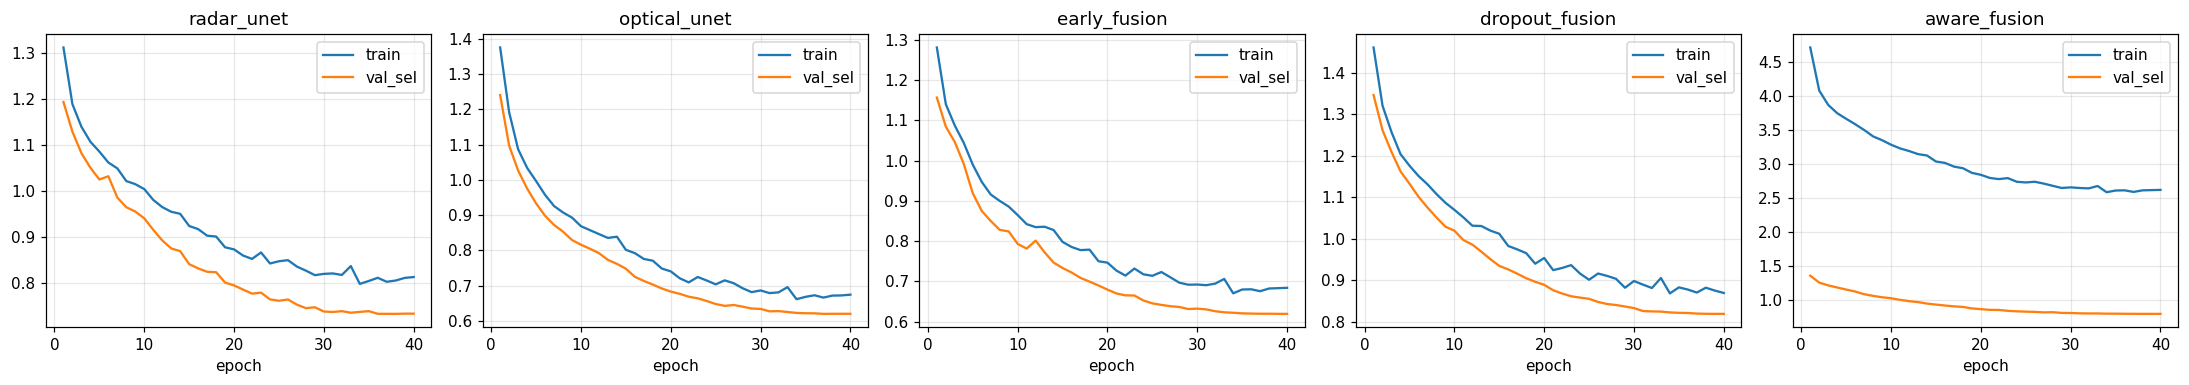

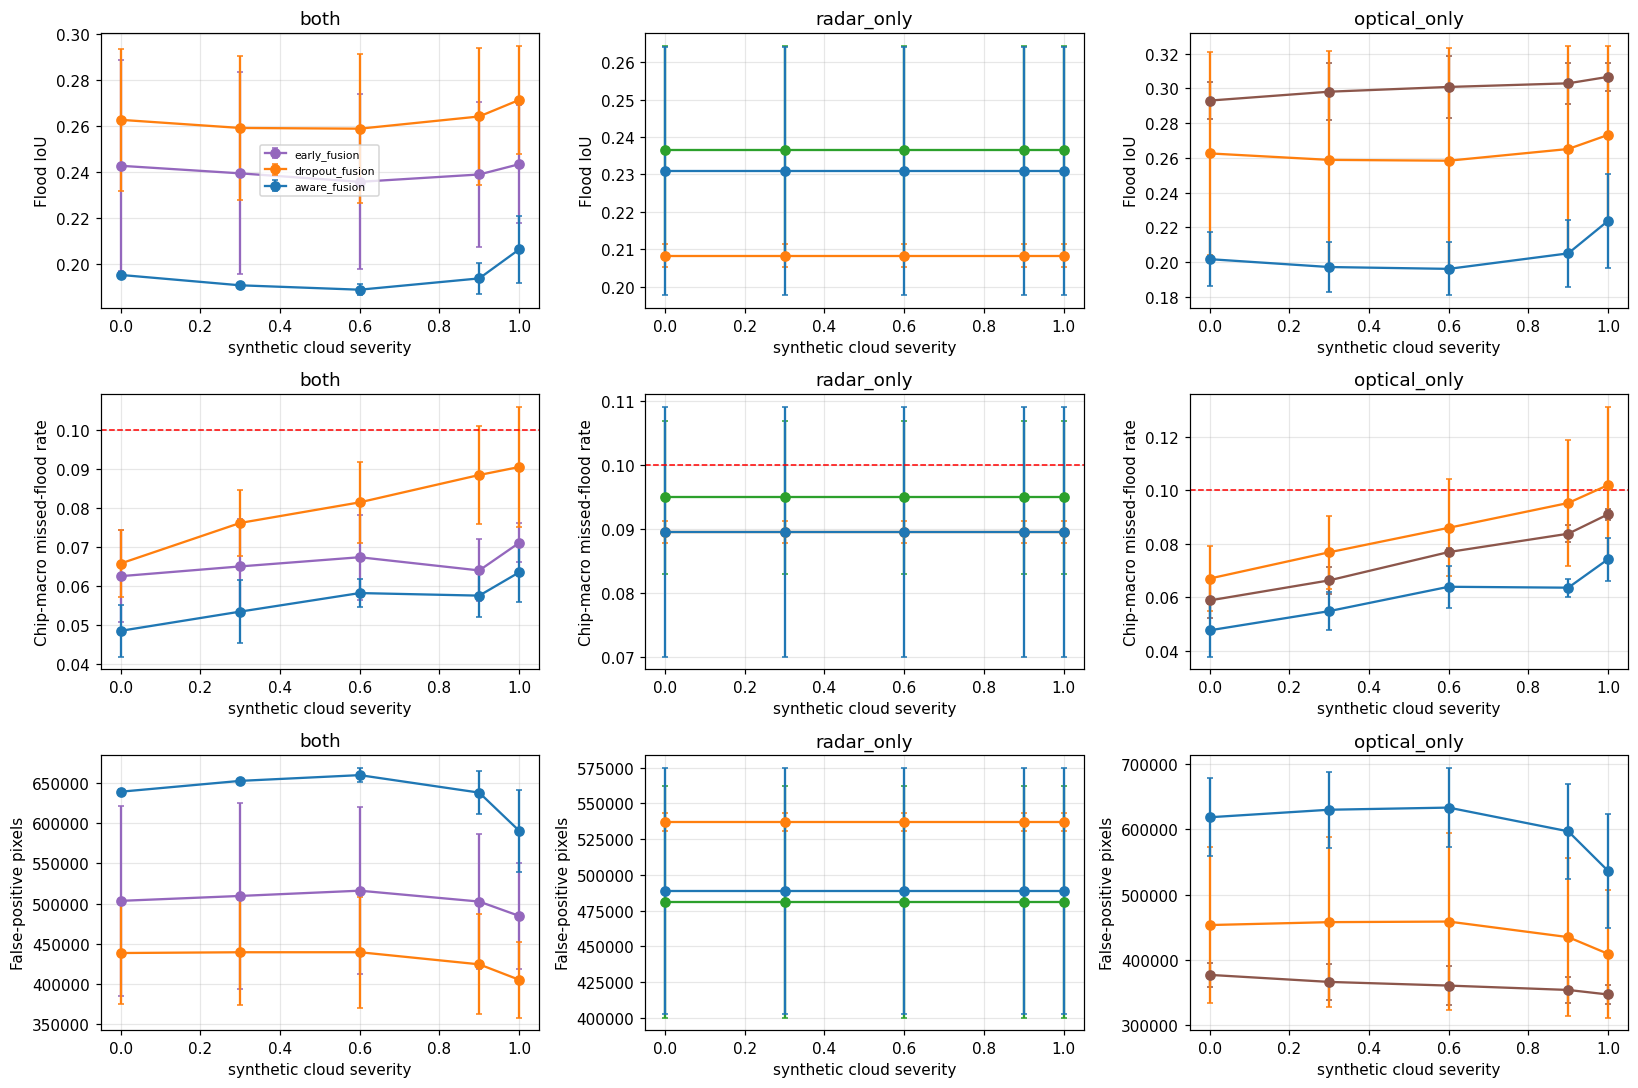

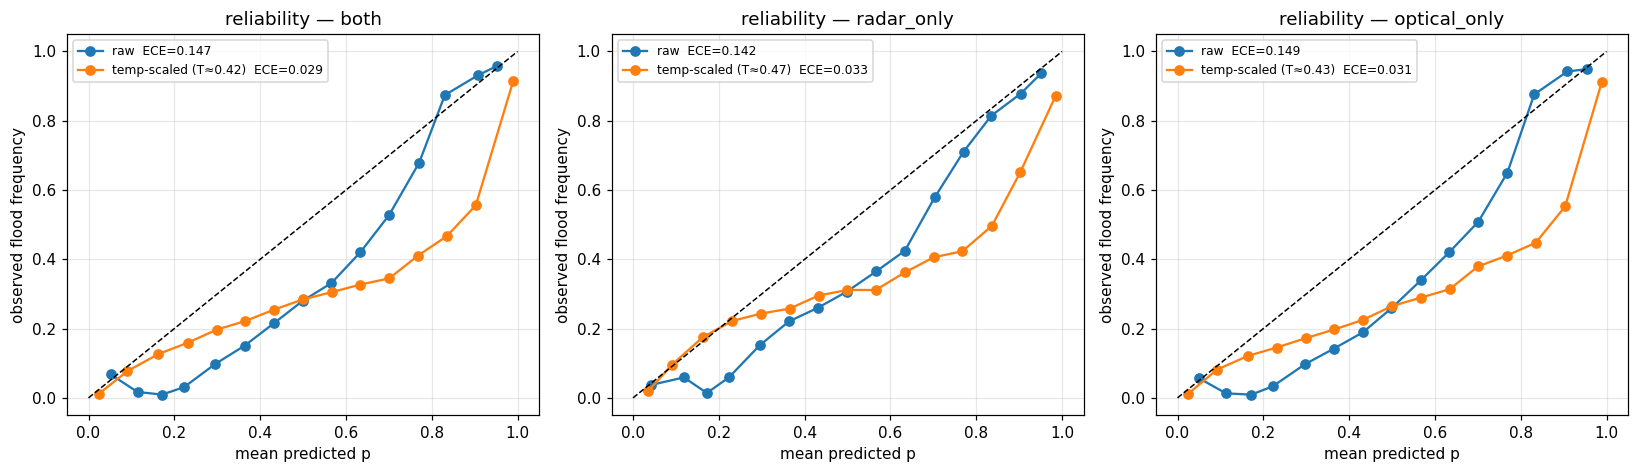

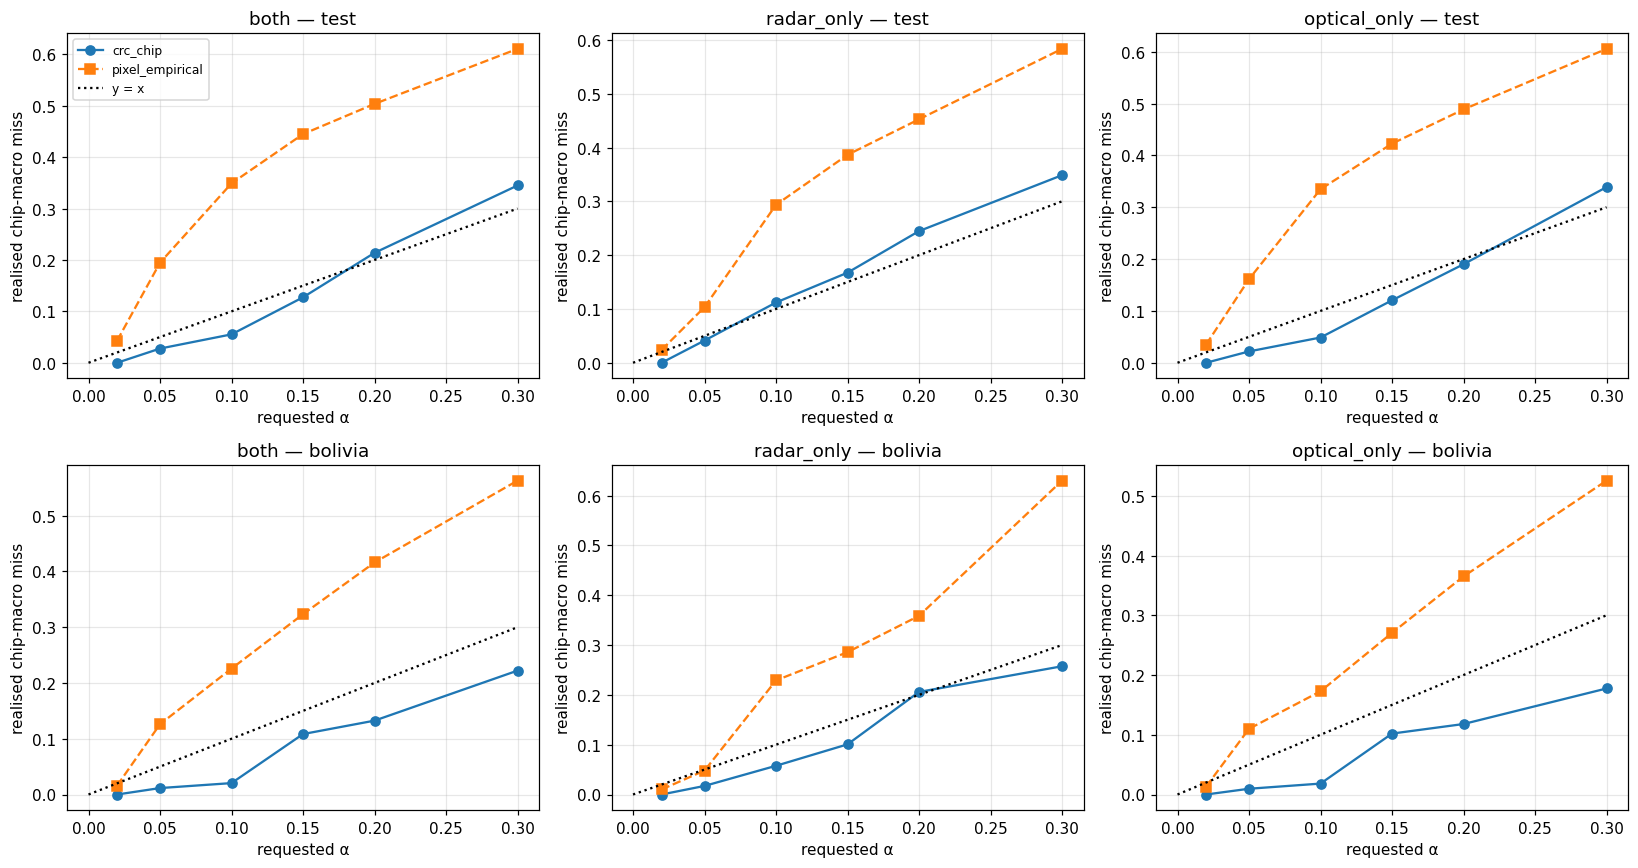

,state,severity,optical_weight_scale1,optical_weight_scale2,optical_weight_scale3
0,both,0.0,0.495,0.838,0.564
1,both,0.3,0.496,0.838,0.566
2,both,0.6,0.497,0.838,0.566
3,both,0.9,0.499,0.837,0.566
4,radar_only,0.0,0.000,0.000,0.000
5,radar_only,0.3,0.000,0.000,0.000
6,radar_only,0.6,0.000,0.000,0.000
7,radar_only,0.9,0.000,0.000,0.000
8,optical_only,0.0,1.000,1.000,1.000
9,optical_only,0.3,1.000,1.000,1.000


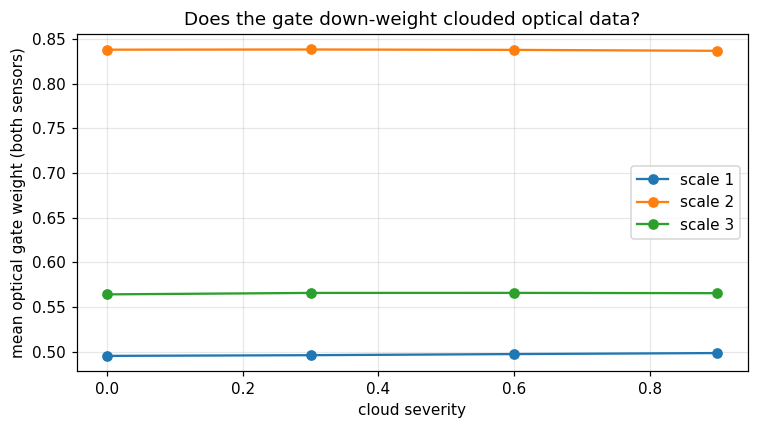

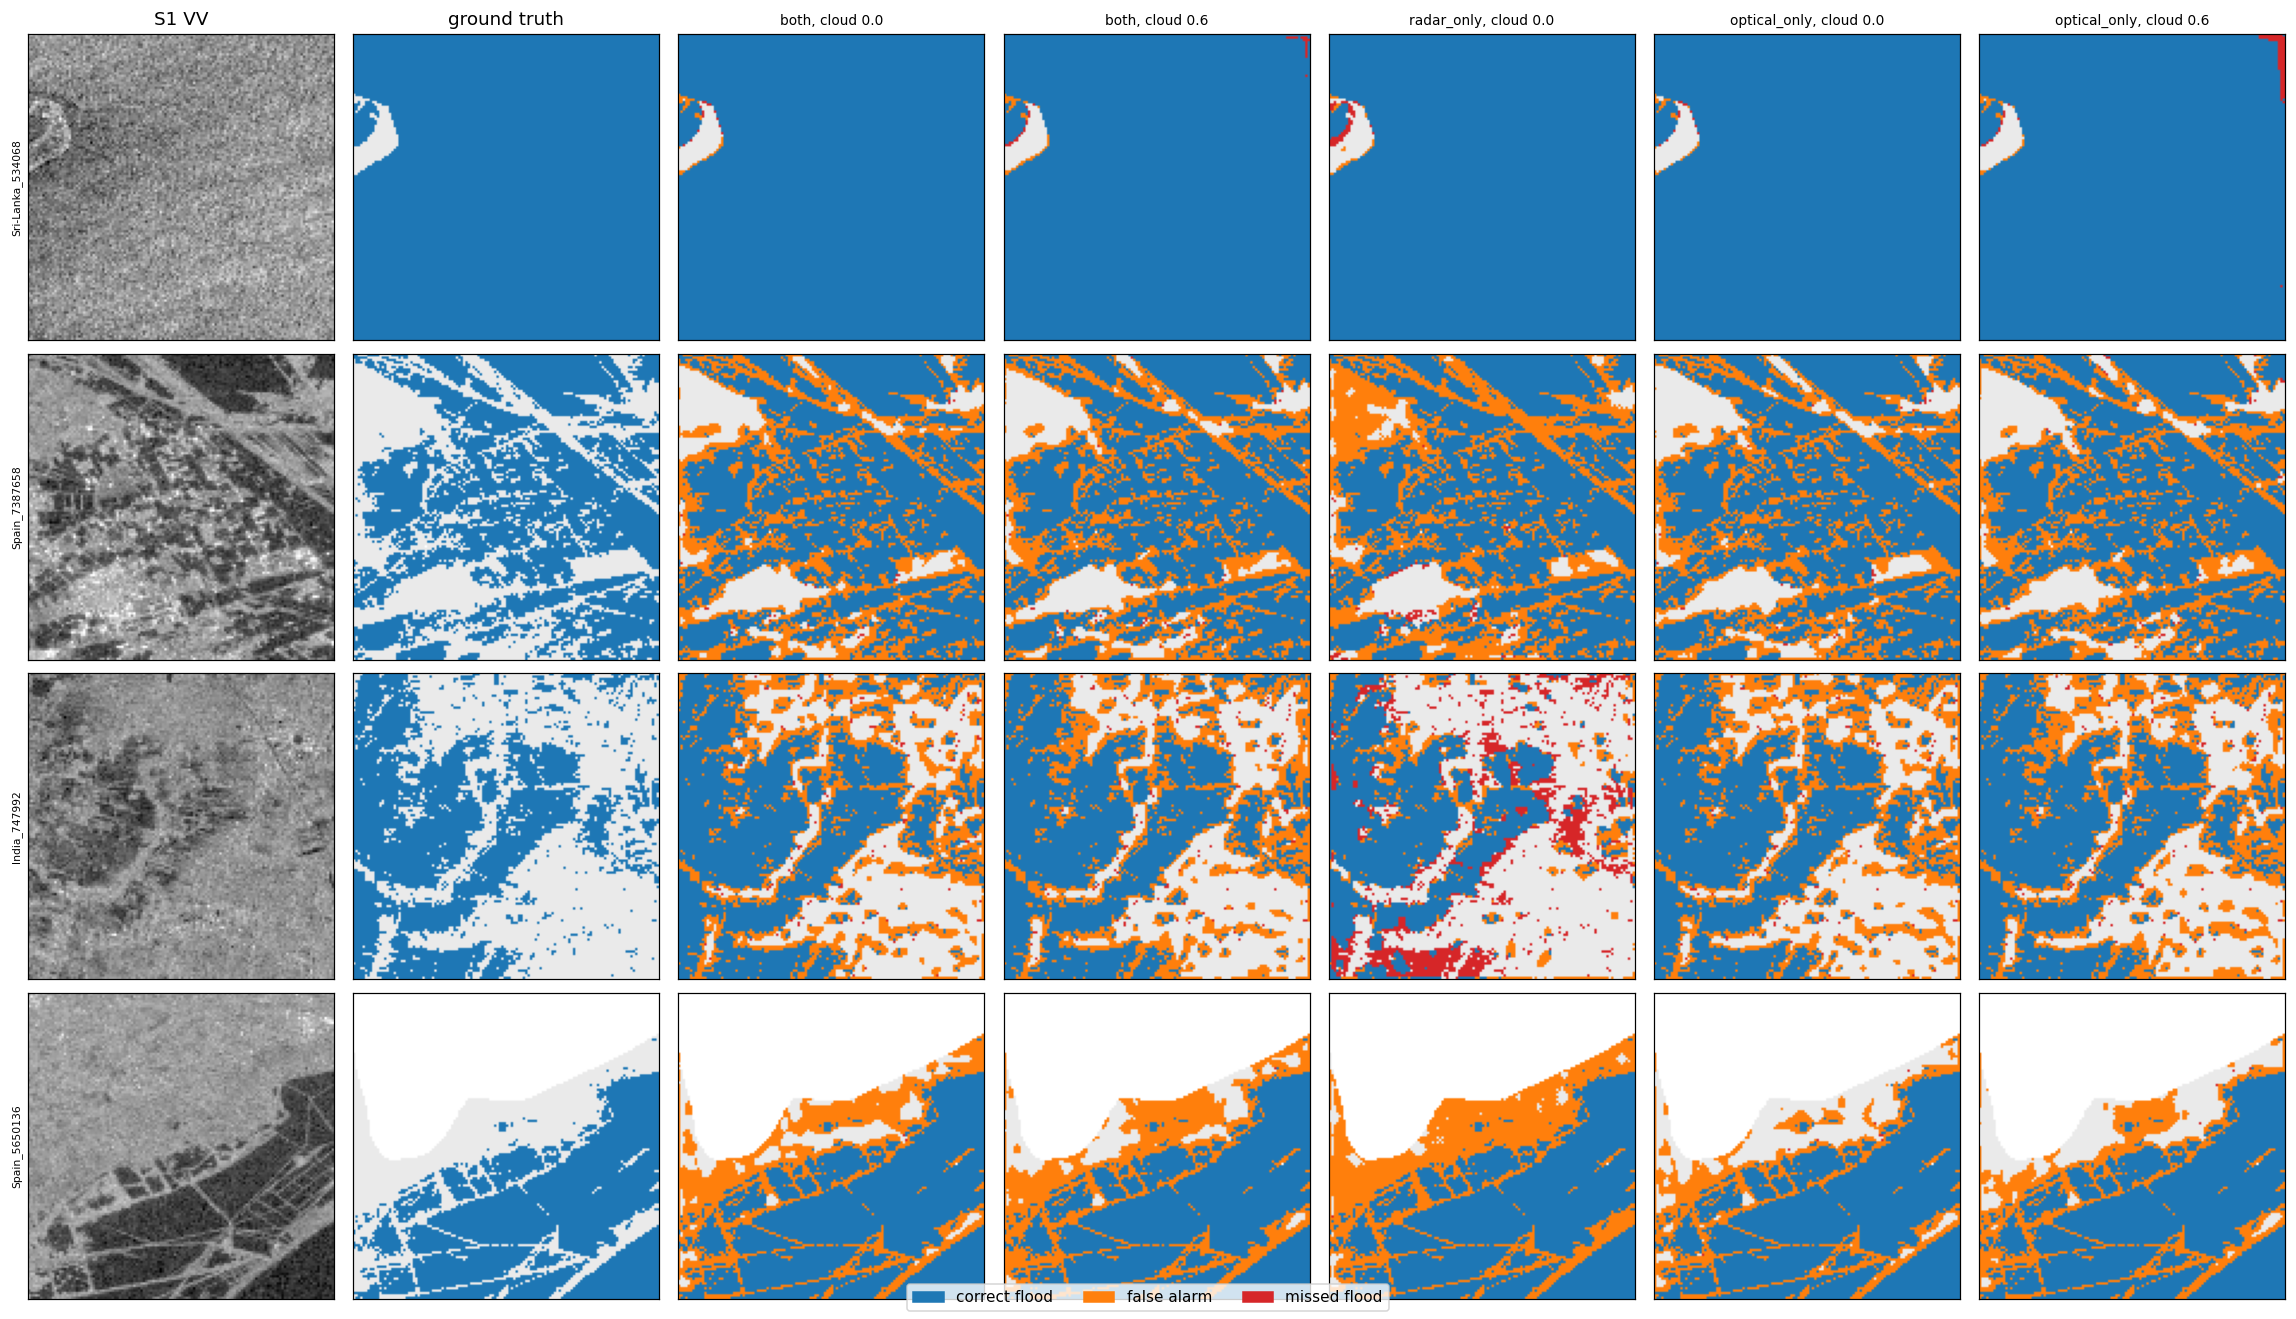

In [28]:
# 19.1 — figures
FIG = RESULTS_DIR / "figures"; plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.grid": True, "grid.alpha": .3})
def savefig(fig, name): fig.tight_layout(); fig.savefig(FIG / f"{RUN_MODE}_{name}.png", bbox_inches="tight"); plt.show()
COL = {"radar_unet": "tab:green", "optical_unet": "tab:brown", "early_fusion": "tab:purple", "dropout_fusion": "tab:orange", "aware_fusion": "tab:blue"}

# Fig 1 training curves (seed 0)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=False)
for ax, n in zip(axes, MAIN_MODELS):
    h = pd.read_csv(RESULTS_DIR/"history"/f"{RUN_MODE}_{n}_s{CFG['seeds'][0]}.csv") if (RESULTS_DIR/"history"/f"{RUN_MODE}_{n}_s{CFG['seeds'][0]}.csv").exists() else None
    if h is None: ax.set_title(f"{n}: history file not found (run was reused/resumed)"); continue
    ax.plot(h.epoch, h.train_loss, label="train"); ax.plot(h.epoch, h.val_loss, label="val_sel"); ax.set_title(n); ax.set_xlabel("epoch"); ax.legend()
savefig(fig, "fig1_training_curves")

# Fig 2 cloud robustness: rows = metric, cols = state; lines = models (mean +- sd over seeds), clear-calibrated CRC thresholds
cs = cloud_summary[cloud_summary.threshold_source == "crc_chip"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for j, st in enumerate(ALL_STATES):
    for i, (met, lab) in enumerate([("IoU", "Flood IoU"), ("miss_rate_chip_macro", "Chip-macro missed-flood rate"), ("FP", "False-positive pixels")]):
        ax = axes[i, j]
        for n in MAIN_MODELS:
            d = cs[(cs.model == n) & (cs.state == st)].sort_values("severity")
            if len(d) == 0: continue
            ax.errorbar(d.severity, d[met + "_mean"], yerr=d[met + "_sd"].fillna(0), marker="o", capsize=2, label=n, color=COL[n])
        if met == "miss_rate_chip_macro": ax.axhline(CFG["target_miss"], c="red", ls="--", lw=1, label="target")
        ax.set_title(f"{st}"); ax.set_ylabel(lab); ax.set_xlabel("synthetic cloud severity")
axes[0, 0].legend(fontsize=7); savefig(fig, "fig2_cloud_robustness")

# Fig 3 reliability diagrams (proposed model seed 0, test): raw vs temperature-scaled
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, st in zip(axes, ALL_STATES):
    L = pred0("test", st, 0.0); Tt = float(cal_tbl[(cal_tbl.model == "aware_fusion") & (cal_tbl.state == st)]["temperature_mean"].iloc[0])
    for lab, P in (("raw", sigmoid_np(L)), (f"temp-scaled (T≈{Tt:.2f})", sigmoid_np(L / Tt))):
        b = bin_stats(P, DATA["test"]["y"]); n_, cf, ac = b["n"].sum(0), b["conf"].sum(0), b["acc"].sum(0); k = n_ > 0
        ax.plot(cf[k] / n_[k], ac[k] / n_[k], marker="o", label=f"{lab}  ECE={ece_from_bins(b):.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"reliability — {st}"); ax.set_xlabel("mean predicted p"); ax.set_ylabel("observed flood frequency"); ax.legend(fontsize=8)
savefig(fig, "fig3_reliability")

# Fig 4 risk-control curve
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, st in enumerate(ALL_STATES):
    for i, split in enumerate(("test", "bolivia")):
        ax = axes[i, j]
        for method, mk in (("crc_chip", "o-"), ("pixel_empirical", "s--")):
            d = risk_curve[(risk_curve.state == st) & (risk_curve.split == split) & (risk_curve.method == method)]
            ax.plot(d.alpha, d.miss_chip_macro, mk, label=f"{method}")
        ax.plot([0, .3], [0, .3], "k:", label="y = x"); ax.set_title(f"{st} — {split}"); ax.set_xlabel("requested α"); ax.set_ylabel("realised chip-macro miss")
axes[0, 0].legend(fontsize=8); savefig(fig, "fig4_risk_control_curve")

# Fig 5 gate weights: mean optical-stream weight per scale, state and cloud severity (proposed model seed 0)
@torch.no_grad()
def mean_gate_weights(model, sev, state, n=64):
    d = DATA["test"]; n = min(n, len(d["ids"])); s2 = np.stack([eval_cloud_s2(d["s2"][i], d["ids"][i], sev, EVAL_CLOUD_SEED) for i in range(n)])
    _, aux = model(torch.from_numpy(d["s1"][:n]).to(DEVICE), torch.from_numpy(np.ascontiguousarray(s2)).to(DEVICE), avail_tensor(state, n))
    return [float(g[:, 1].float().mean()) for g in aux["gates"]]
gm = get_model("aware_fusion", CFG["seeds"][0]); gate_rows = []
for st in ALL_STATES:
    for sev in (0.0, 0.3, 0.6, 0.9):
        gate_rows.append(dict(state=st, severity=sev, **{f"optical_weight_scale{k+1}": w for k, w in enumerate(mean_gate_weights(gm, sev, st))}))
gate_df = pd.DataFrame(gate_rows); gate_df.to_csv(RESULTS_DIR/"evaluation"/f"gate_weights_{RUN_MODE}.csv", index=False); display(gate_df.round(3))
fig, ax = plt.subplots(figsize=(7, 4)); gd = gate_df[gate_df.state == "both"]
for k in range(3): ax.plot(gd.severity, gd[f"optical_weight_scale{k+1}"], marker="o", label=f"scale {k+1}")
ax.set_xlabel("cloud severity"); ax.set_ylabel("mean optical gate weight (both sensors)"); ax.set_title("Does the gate down-weight clouded optical data?"); ax.legend()
savefig(fig, "fig5_gate_weights")

# Fig 6 qualitative error maps (test chips with most flood), proposed model, clear vs cloud 0.6 vs radar-only vs optical-only
def error_map(pred, truth):
    valid = truth != IGNORE_INDEX; t = truth == 1; img = np.full(pred.shape + (3,), 0.92)
    img[pred & t] = [.12, .47, .71]; img[pred & ~t & valid] = [1., .5, .05]; img[~pred & t] = [.84, .15, .16]; img[~valid] = 1; return img
thr_by_state = dict(zip(thr_report.state, thr_report.crc_threshold))
dt = DATA["test"]; order = np.argsort(-(dt["y"] == 1).sum((1, 2)))[:12]; picks = order[np.linspace(0, len(order) - 1, 4).astype(int)]
cases = [("both", 0.0), ("both", 0.6), ("radar_only", 0.0), ("optical_only", 0.0), ("optical_only", 0.6)]
L_all = {cs_: pred0("test", *cs_) for cs_ in cases}
fig, axes = plt.subplots(len(picks), 2 + len(cases), figsize=(3 * (2 + len(cases)), 3 * len(picks)), squeeze=False)
for r, i in enumerate(picks):
    axes[r, 0].imshow(dt["s1"][i][0], cmap="gray"); axes[r, 1].imshow(error_map(dt["y"][i] == 1, dt["y"][i]))
    for c_, cs_ in enumerate(cases):
        axes[r, 2 + c_].imshow(error_map(sigmoid_np(L_all[cs_][i]) >= thr_by_state[cs_[0]], dt["y"][i]))
        if r == 0: axes[r, 2 + c_].set_title(f"{cs_[0]}, cloud {cs_[1]}", fontsize=9)
    axes[r, 0].set_ylabel(dt["ids"][i], fontsize=7)
axes[0, 0].set_title("S1 VV"); axes[0, 1].set_title("ground truth")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=(.12, .47, .71), label="correct flood"), Patch(color=(1, .5, .05), label="false alarm"), Patch(color=(.84, .15, .16), label="missed flood")], loc="lower center", ncol=3)
savefig(fig, "fig6_qualitative")

## 20. Results export
All tables are already written as CSV during the run; this cell zips the whole `results/` tree and writes a manifest.

In [29]:
# 20.1 — manifest + zip
files = sorted(str(p.relative_to(RESULTS_DIR)) for p in RESULTS_DIR.rglob("*") if p.is_file() and p.suffix in (".csv", ".json", ".png", ".pt"))
json.dump({"run_mode": RUN_MODE, "files": files}, open(RESULTS_DIR/"config"/f"manifest_{RUN_MODE}.json", "w"), indent=2)
print(len(files), "result files; examples:", files[:6])
zip_path = shutil.make_archive(str(PROJECT_DIR / f"results_{RUN_MODE}"), "zip", RESULTS_DIR); print("zip:", zip_path)

107 result files; examples: ['ablations/ablation_rows_one_day.csv', 'ablations/ablation_summary_one_day.csv', 'ablations/threshold_per_state_vs_global_one_day.csv', 'cache_meta/cache_benchmark.json', 'cache_meta/cache_meta.json', 'calibration/mc_dropout_uncertainty_one_day.csv']
zip: /kaggle/working/FloodMappingProject/results_one_day.zip


## 21. Reproducibility metadata and an *auto-derived* status report
The status table below is computed from the objects that actually exist in this session (trained models, tables), so it cannot claim an experiment that was not run.

In [30]:
# 21.1 — config + environment + executed-experiment inventory
executed = dict(
    models_trained={n: sorted(s for (m, s) in TRAINED if m == n) for n in sorted({m for (m, _) in TRAINED})},
    main_eval_rows=len(eval_main), cloud_rows=len(all_cloud), ablation_models_in_table=sorted(abl_summary.model.unique()),
    ensemble_evaluated="aware_fusion_ensemble" in set(eval_main.model), mc_dropout_evaluated="aware_fusion_mcdropout" in set(eval_main.model),
    resplit_diagnostic=len(diag) > 0, severities=list(CFG["eval_severities"]),
    ablations_requested_but_not_trained=[m for m in ABLATION_MODELS + EXTRA_ABLATIONS if not any(k[0] == m for k in TRAINED)],
)
meta = dict(run_mode=RUN_MODE, cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}, preproc=PREPROC, split_hash=SPLIT_HASH,
            split_counts={k: len(v) for k, v in SPLIT_IDS.items()}, param_counts=params, cache=json.load(open(RESULTS_DIR/"cache_meta"/"cache_meta.json")),
            executed=executed, torch=torch.__version__, numpy=np.__version__, pandas=pd.__version__, rasterio=rasterio.__version__,
            device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
            statements=["Synthetic cloud = stress test.", "CRC guarantee is marginal, chip-level, conditional on flood-containing chips; exchangeability only approximate; "
                        "not valid under shift (Bolivia).", "No Bangladesh data used.", "FP area is approximate (metadata-derived).",
                        "Single dataset, small labelled set: report seed variance + chip bootstrap, not point estimates."])
json.dump(meta, open(RESULTS_DIR/"config"/f"experiment_config_{RUN_MODE}.json", "w"), indent=2, default=str)
print(json.dumps(executed, indent=2))

{
  "models_trained": {
    "aware_fusion": [
      0,
      1,
      2
    ],
    "aware_no_consistency": [
      0,
      1,
      2
    ],
    "aware_no_embedding": [
      0,
      1,
      2
    ],
    "aware_no_gate": [
      0,
      1,
      2
    ],
    "aware_no_opthead": [
      0,
      1,
      2
    ],
    "dropout_fusion": [
      0,
      1,
      2
    ],
    "early_fusion": [
      0,
      1,
      2
    ],
    "optical_unet": [
      0,
      1,
      2
    ],
    "radar_unet": [
      0,
      1,
      2
    ]
  },
  "main_eval_rows": 198,
  "cloud_rows": 954,
  "ablation_models_in_table": [
    "aware_fusion",
    "aware_no_consistency",
    "aware_no_embedding",
    "aware_no_gate",
    "aware_no_opthead",
    "dropout_fusion"
  ],
  "ensemble_evaluated": true,
  "mc_dropout_evaluated": true,
  "resplit_diagnostic": true,
  "severities": [
    0.0,
    0.3,
    0.6,
    0.9,
    1.0
  ],
  "ablations_requested_but_not_trained": [
    "aware_no_calterm",
    "awar

## 22. Optional deployment bundle
Exports the proposed model (first seed), its flags, and the **per-state CRC thresholds** with the exact guarantee wording. Intended for the optional Gradio demo (not built here).

In [31]:
# 22.1 — deployment export
DEPLOY = PROJECT_DIR / "deploy"; (DEPLOY / "demo_chips").mkdir(parents=True, exist_ok=True)
seed0 = CFG["seeds"][0]; m = get_model("aware_fusion", seed0)
torch.save(dict(model_state_dict={k: v.detach().cpu() for k, v in m.state_dict().items()}, model_class="SensorAwareFusionUNet",
                config=dict(base=CFG["base"], drop_p=CFG["drop_p"], flags=SPECS["aware_fusion"]["flags"], s2_channels=13, img_size=IMG_SIZE),
                thresholds_crc_chip=thr_by_state, target_miss=CFG["target_miss"], seed=seed0, run_mode=RUN_MODE, split_hash=SPLIT_HASH,
                guarantee_text=("Expected per-chip missed-flood fraction <= target for flood-containing chips exchangeable with the calibration chips; "
                                "not per-pixel/per-image/per-event; not valid under distribution shift."),
                preproc=PREPROC), DEPLOY / "fusion_deploy.pt")
for cid in DATA["test"]["ids"][:2]:
    for p in (s1_files[cid], s2_files[cid]): shutil.copy2(p, DEPLOY / "demo_chips")
print("deployment bundle:", shutil.make_archive(str(PROJECT_DIR / "deploy_bundle"), "zip", DEPLOY))

deployment bundle: /kaggle/working/FloodMappingProject/deploy_bundle.zip


## Appendix — coverage and limitations (static statement; the executed inventory is in Section 21)
**Implemented in this notebook (code present):** three availability states in training and evaluation; availability embedding used in gate and FiLM; masked softmax gate (zero weight for missing sensors); radar→optical feature head (supervised on clean optical features, radar-only input); radar-only/optical-only/early-fusion baselines; plain sensor-dropout baseline; consistency (teacher-detached), Brier calibration term; per-state calibration split disjoint from model selection and test; chip-level conformal risk control (B=1) + labelled empirical alternatives; Brier/ECE/reliability/temperature scaling; MC-Dropout; deep ensemble over seeds; cloud sweep; chip-bootstrap CIs; ablation runners; persistent fingerprinted cache; resumable, compatibility-checked checkpoints.

**Deferred / not done:** fine-tuned pretrained geospatial model (memory + time); leave-one-event-out runs (a loop over `carve`/splits that multiplies training cost by the number of events); capacity-matched baselines; real-cloud (e.g. s2cloudless / cloud-mask) evaluation; a Bangladesh-specific external test; Gradio app; `torch.compile` benefits (not measured); per-seed paired significance tests.

**Authoring-time verification:** syntax (AST) of every code cell and NumPy-only unit tests (metrics, ECE, temperature scaling, thresholding, conformal Monte-Carlo check, cache fingerprint logic) were executed in a sandbox *without* PyTorch, GPU, network or dataset. Everything that needs torch/rasterio/data (model self-tests in §9–10, checkpoint test in §12.3, cache equivalence in §6.2, all training and results) is **implemented but unexecuted by the author** and will run for the first time on your Colab session.